In [1]:
# 1. Environment Setup, Plot Styling & Palette Configuration
import os
import sys
import time
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Suppress harmless runtime warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# High-resolution rendering & typography configuration
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'

# Semantic Palette for Collision Severity (Consistent across all charts)
SEVERITY_PALETTE = {
    'Slight': '#2b5c8f',    # Steel Blue (dominant, lowest harm)
    'Serious': '#e28743',   # Amber Orange (intermediate harm)
    'Fatal': '#c0392b'      # Crimson Red (lethal harm)
}

SEVERITY_ORDER = ['Slight', 'Serious', 'Fatal']

# Figures export directory
FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)



In [2]:
# 2. Ingest Cleaned Parquet Dataset
DATA_PATH = Path('data/processed/cleaned_collisions_2019_2023.parquet')
if not DATA_PATH.exists():
    DATA_PATH = Path('../data/processed/cleaned_collisions_2019_2023.parquet')

df = pd.read_parquet(DATA_PATH)
missing_count = df.isnull().sum().sum()
print(f'Dataset shape: {df.shape}, Total nulls: {missing_count}')


Dataset shape: (519991, 47), Total nulls: 0


In [3]:
# 3. Target Severity Distribution, Annual Temporal Breakdown & Chi-Square Homogeneity Test
target_counts = df['collision_severity_label'].value_counts()[SEVERITY_ORDER]
target_pcts = df['collision_severity_label'].value_counts(normalize=True)[SEVERITY_ORDER] * 100

target_summary = pd.DataFrame({
    'Raw Count': target_counts,
    'Proportion (%)': target_pcts
})
target_summary['Cumulative (%)'] = target_summary['Proportion (%)'].cumsum()

display(target_summary.style.format({'Raw Count': '{:,}', 'Proportion (%)': '{:.2f}%', 'Cumulative (%)': '{:.2f}%'}))

# Compute annual breakdown
annual_dist = pd.crosstab(df['collision_year'], df['collision_severity_label'])[SEVERITY_ORDER]
annual_pcts = pd.crosstab(df['collision_year'], df['collision_severity_label'], normalize='index')[SEVERITY_ORDER] * 100

annual_summary = annual_dist.copy()
annual_summary['Total Collisions'] = annual_summary.sum(axis=1)
annual_summary['Fatal %'] = annual_pcts['Fatal']
annual_summary['Serious %'] = annual_pcts['Serious']
annual_summary['Slight %'] = annual_pcts['Slight']

display(annual_summary.style.format({
    'Slight': '{:,}', 'Serious': '{:,}', 'Fatal': '{:,}', 
    'Total Collisions': '{:,}', 'Fatal %': '{:.2f}%', 
    'Serious %': '{:.2f}%', 'Slight %': '{:.2f}%'
}))

# Chi-Square Test of Homogeneity across Years
chi2, p_val, dof, ex = stats.chi2_contingency(annual_dist)
print(f'Chi2 Homogeneity Test (Years): Chi2 = {chi2:.2f}, dof = {dof}, p-value = {p_val:.4e}')


,Raw Count,Proportion (%),Cumulative (%)
collision_severity_label,,,
Slight,"402,976",77.50%,77.50%
Serious,"109,369",21.03%,98.53%
Fatal,"7,646",1.47%,100.00%


collision_severity_label,Slight,Serious,Fatal,Total Collisions,Fatal %,Serious %,Slight %
collision_year,,,,,,,
2019,"92,874","22,976","1,658","117,508",1.41%,19.55%,79.04%
2020,"71,441","18,353","1,391","91,185",1.53%,20.13%,78.35%
2021,"78,318","21,279","1,473","101,070",1.46%,21.05%,77.49%
2022,"81,053","23,327","1,602","105,982",1.51%,22.01%,76.48%
2023,"79,290","23,434","1,522","104,246",1.46%,22.48%,76.06%


Chi2 Homogeneity Test (Years): Chi2 = 402.36, dof = 8, p-value = 5.8475e-82


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


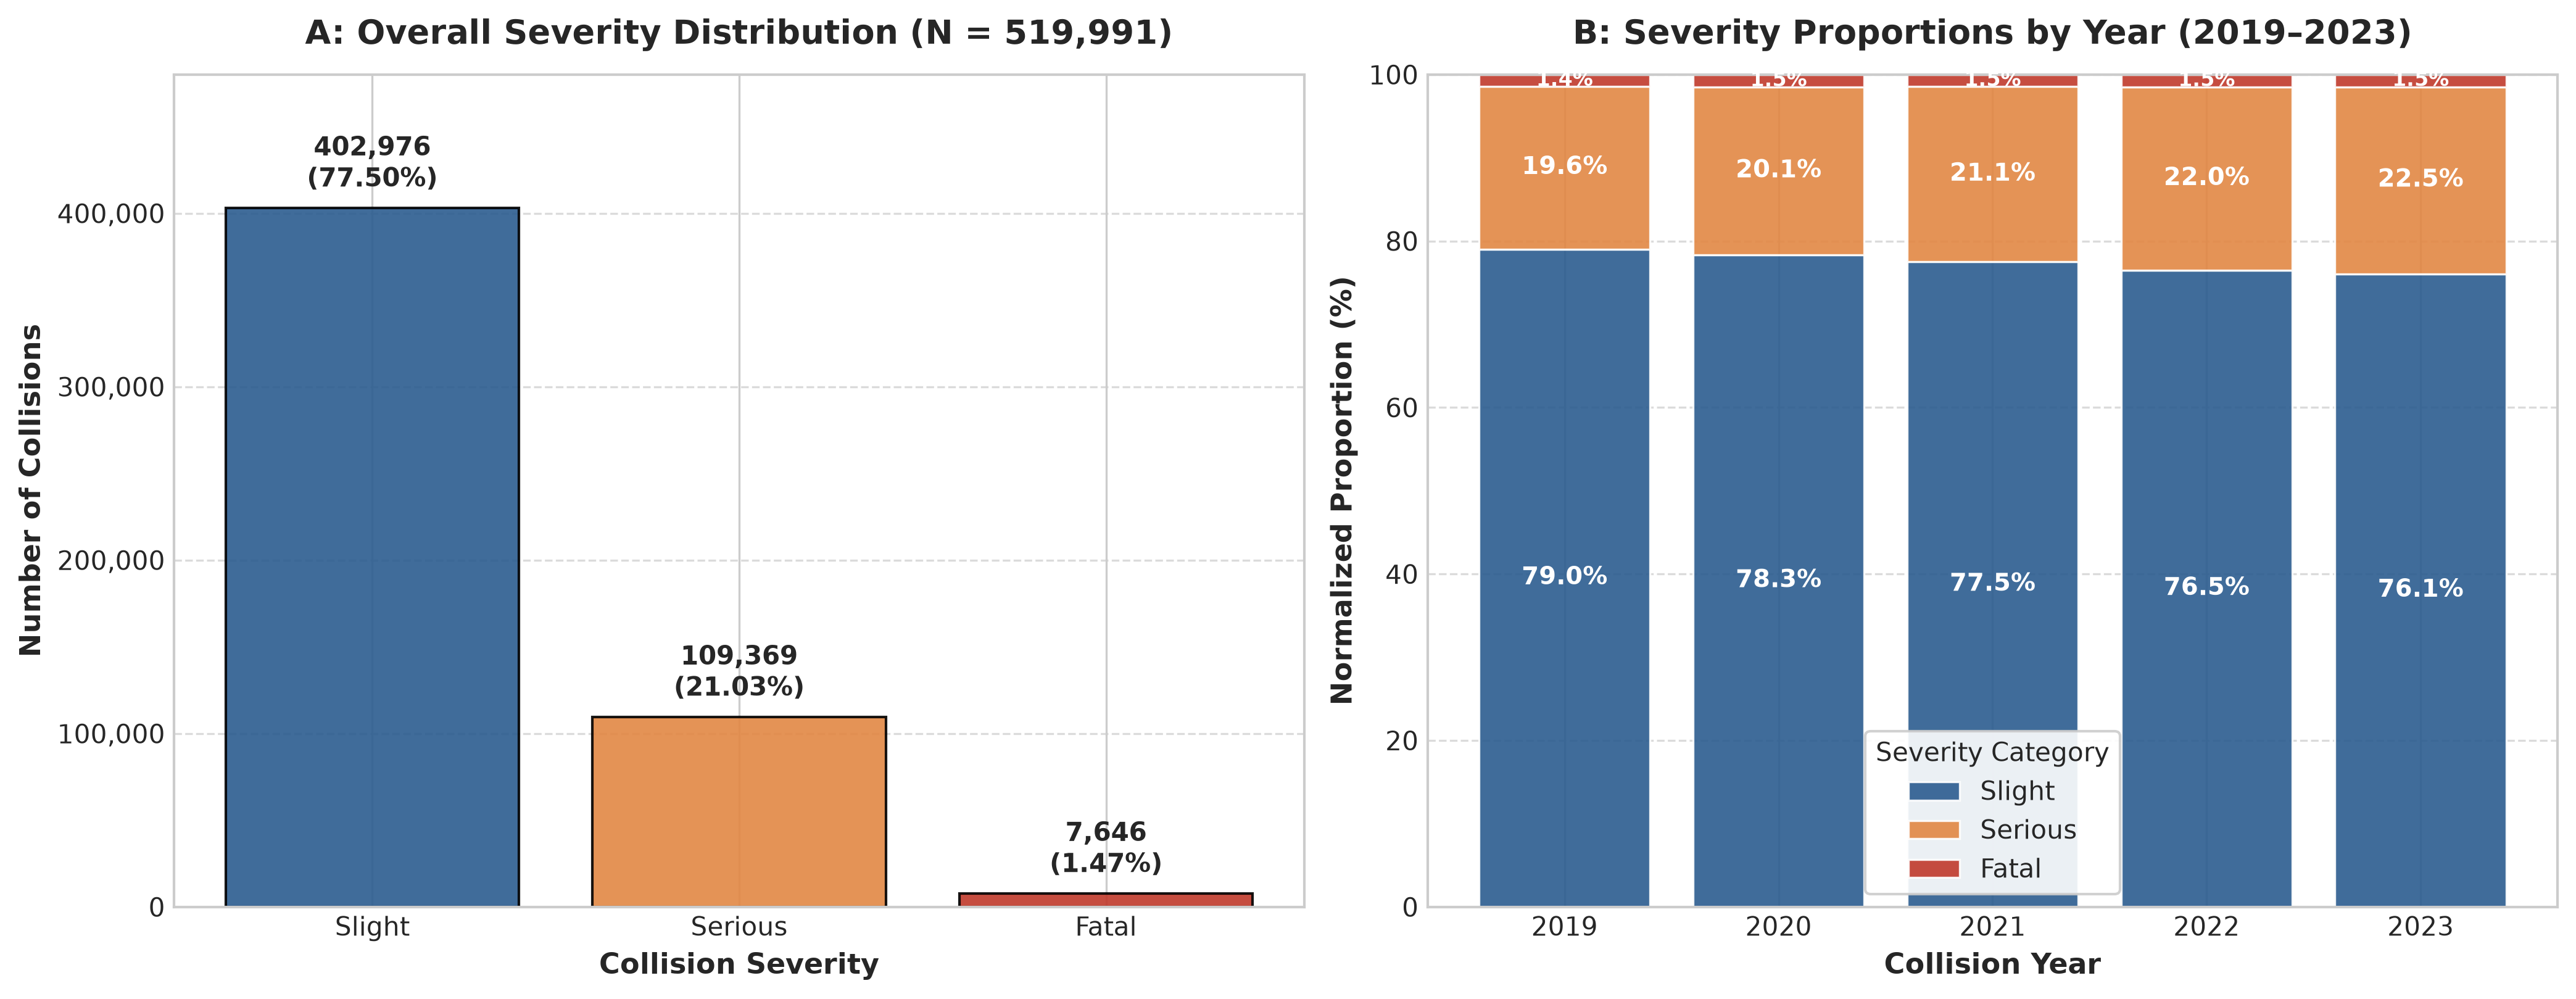

In [4]:
# 4. Plot: Target Severity Distribution & 100% Normalized Annual Stacked Bars
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Overall Class Imbalance Bar Chart
bars = ax1.bar(target_summary.index, target_summary['Raw Count'], 
               color=[SEVERITY_PALETTE[s] for s in target_summary.index], 
               edgecolor='black', linewidth=1, alpha=0.9)
ax1.set_title("A: Overall Severity Distribution (N = 519,991)", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("Collision Severity", fontweight='semibold')
ax1.set_ylabel("Number of Collisions", fontweight='semibold')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x):,}'))
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate counts and percentages on top of bars
for bar, (label, row) in zip(bars, target_summary.iterrows()):
    height = bar.get_height()
    ax1.annotate(f"{int(row['Raw Count']):,}\n({row['Proportion (%)']:.2f}%)",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_ylim(0, 480000)

# Panel B: 100% Normalized Stacked Bar Chart by Year
bottom = np.zeros(len(annual_pcts))
years = [str(y) for y in annual_pcts.index]
for sev in SEVERITY_ORDER:
    values = annual_pcts[sev].values
    ax2.bar(years, values, bottom=bottom, label=sev, 
            color=SEVERITY_PALETTE[sev], edgecolor='white', linewidth=0.8, alpha=0.9)
    # Label inside stack if height allows
    for i, val in enumerate(values):
        if val > 6:
            ax2.text(i, bottom[i] + val / 2, f"{val:.1f}%", 
                     ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
        elif val > 1:
            ax2.text(i, bottom[i] + val / 2, f"{val:.1f}%", 
                     ha='center', va='center', color='white', fontweight='bold', fontsize=8)
    bottom += values

ax2.set_title("B: Severity Proportions by Year (2019–2023)", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Collision Year", fontweight='semibold')
ax2.set_ylabel("Normalized Proportion (%)", fontweight='semibold')
ax2.set_ylim(0, 100)
ax2.legend(title="Severity Category", frameon=True, facecolor='white', framealpha=0.9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig1_target_distribution_and_annual_stability.png"
plt.savefig(fig_path)
plt.show()



findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


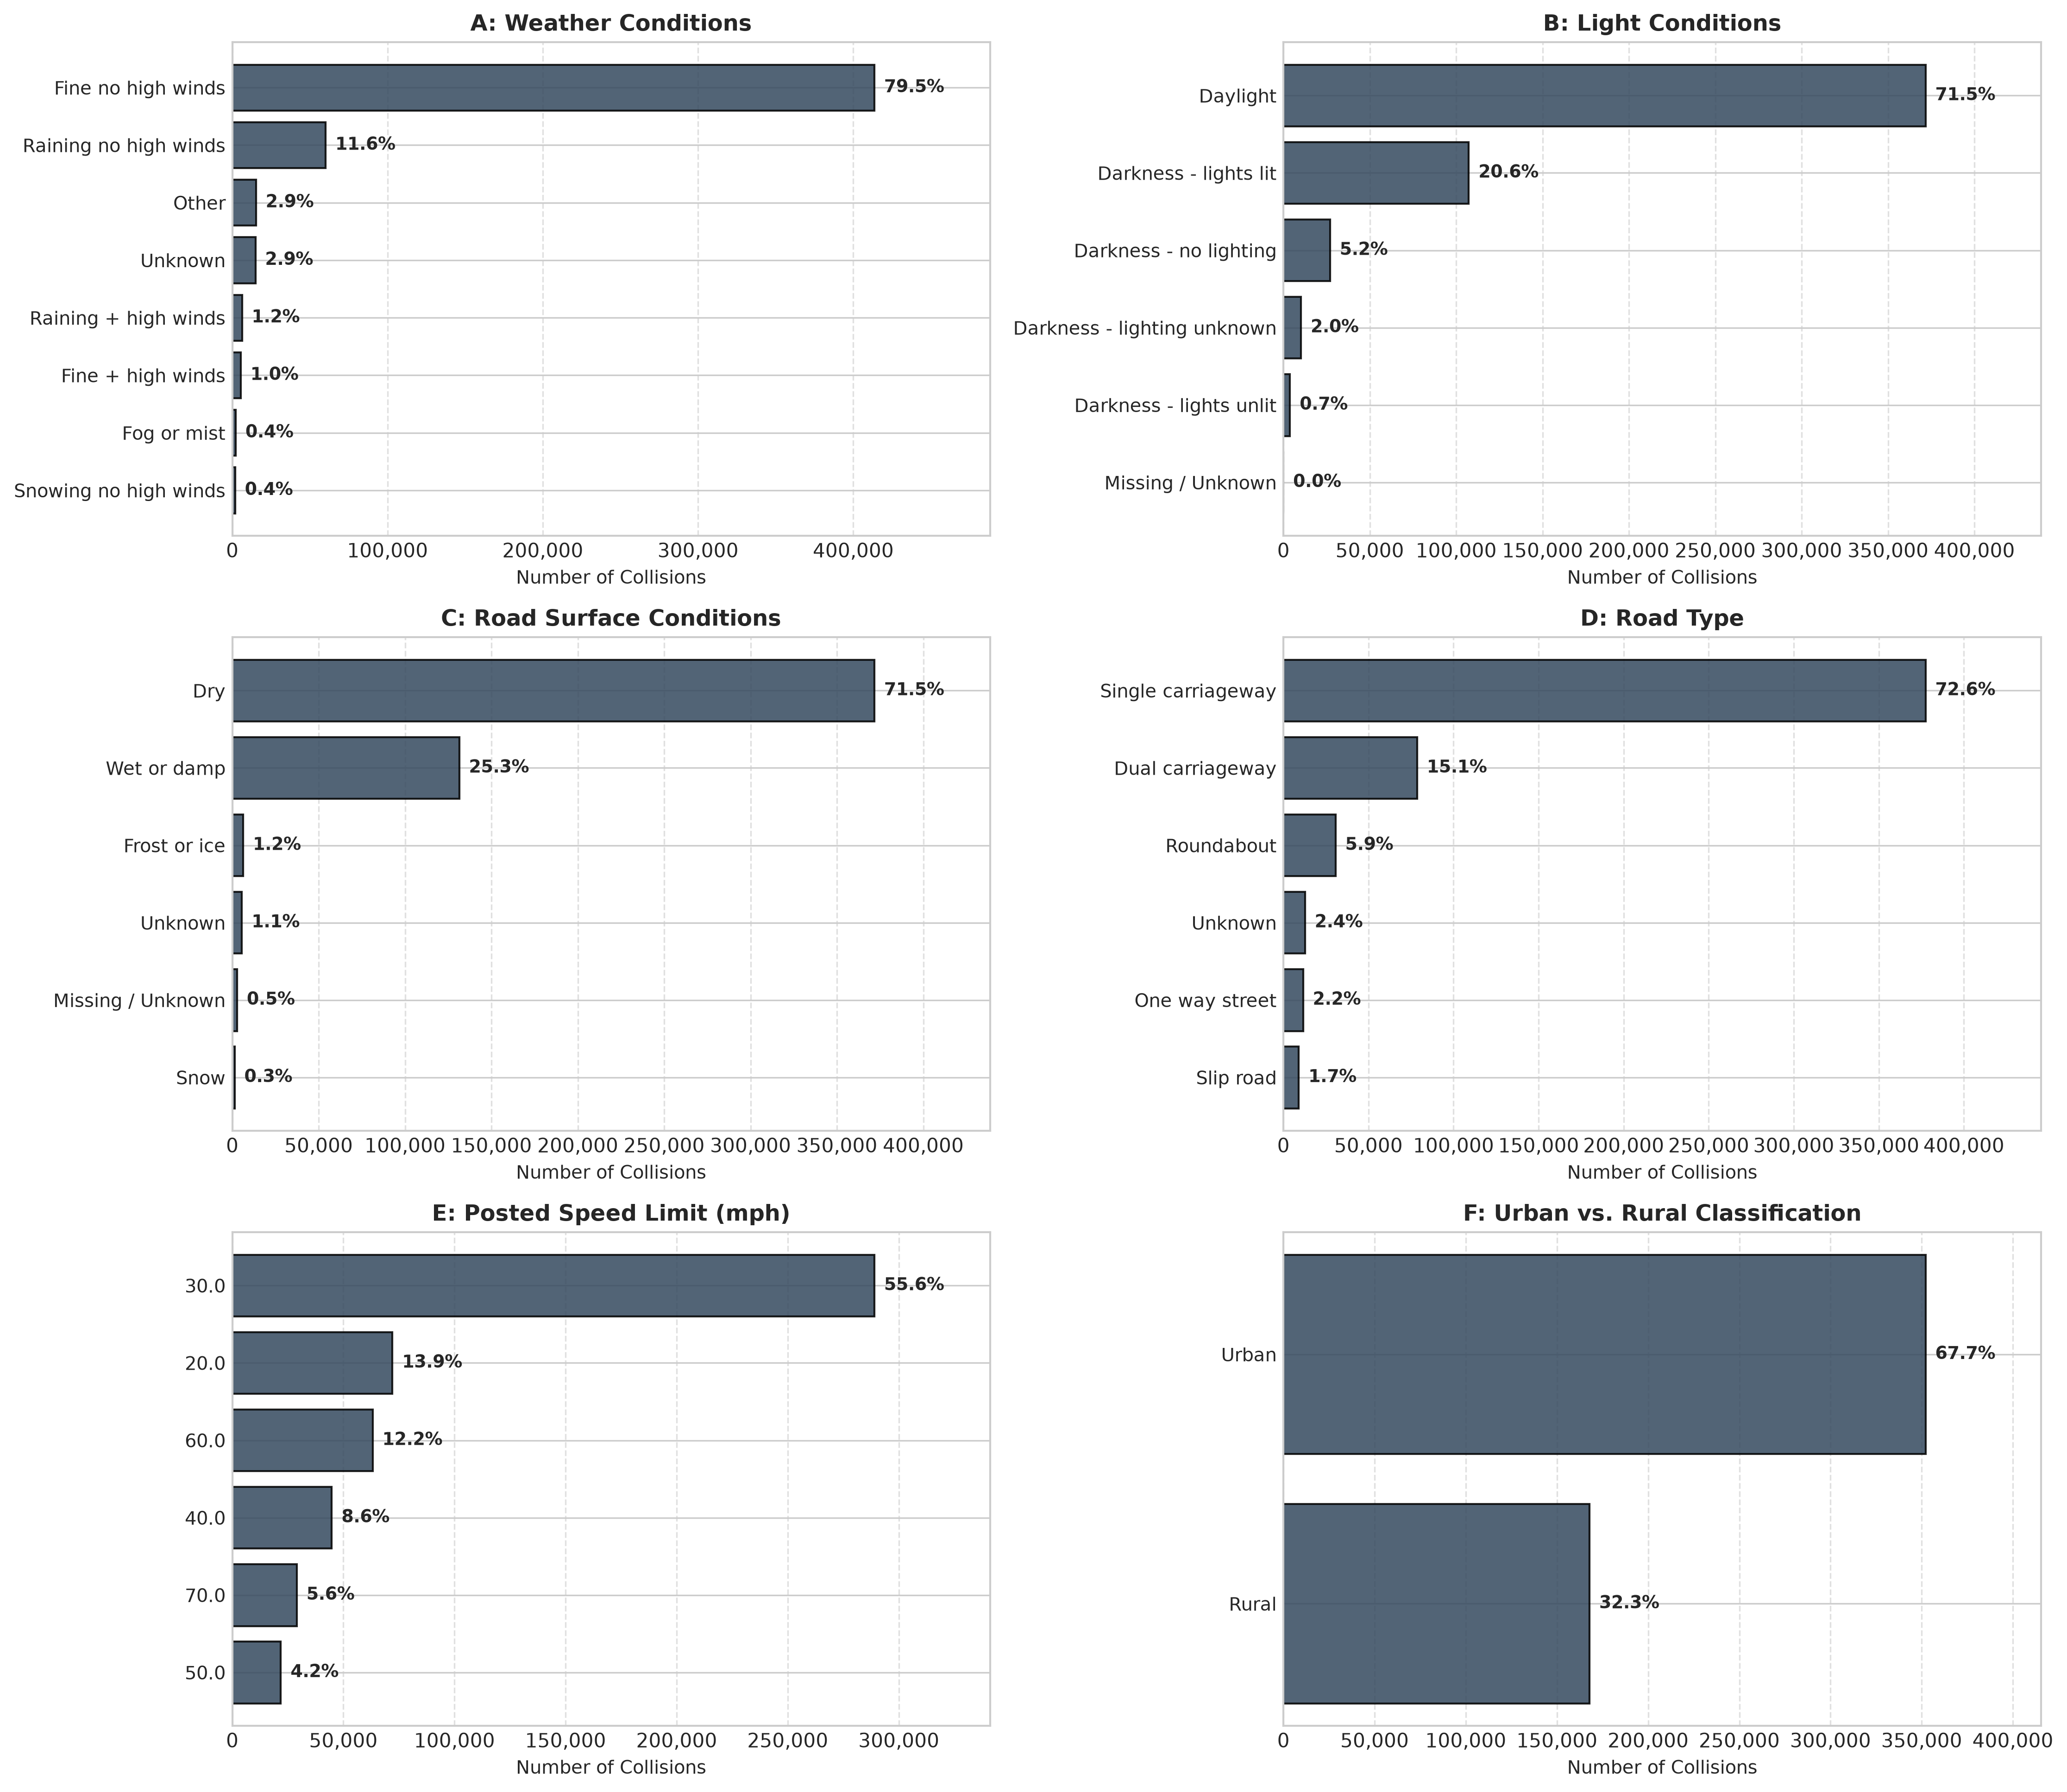

In [5]:
# 5. Plot: Univariate Circumstance Landscape (Weather, Light, Surface, Road Type, Speed, Urban/Rural)
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

univariate_cols = [
    ('weather_conditions_label', 'Weather Conditions', 8),
    ('light_conditions_label', 'Light Conditions', 6),
    ('road_surface_conditions_label', 'Road Surface Conditions', 6),
    ('road_type_label', 'Road Type', 6),
    ('speed_limit', 'Posted Speed Limit (mph)', 7),
    ('urban_or_rural_area_label', 'Urban vs. Rural Classification', 3)
]

for idx, (col, title, top_n) in enumerate(univariate_cols):
    ax = axes[idx]
    val_counts = df[col].value_counts().head(top_n)
    val_pcts = (val_counts / len(df)) * 100
    
    y_pos = np.arange(len(val_counts))
    bars = ax.barh(y_pos, val_counts.values, color='#34495e', edgecolor='black', alpha=0.85)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([str(label) for label in val_counts.index], fontsize=9.5)
    ax.invert_yaxis()  # Top-down order
    ax.set_title(f"{chr(65+idx)}: {title}", fontsize=11.5, fontweight='bold')
    ax.set_xlabel("Number of Collisions", fontsize=9.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x):,}'))
    ax.grid(axis='x', linestyle='--', alpha=0.6)
    
    # Annotate percentages
    max_x = val_counts.max()
    for bar, pct in zip(bars, val_pcts):
        width = bar.get_width()
        ax.annotate(f"{pct:.1f}%",
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points",
                    ha='left', va='center', fontsize=9, fontweight='semibold')
    ax.set_xlim(0, max_x * 1.18)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig2_univariate_circumstance_landscape.png"
plt.savefig(fig_path)
plt.show()



In [6]:
# 6. Bivariate Analysis: Environmental Risk vs. Exposure (Chi-Square & Cramér's V)
def compute_bivariate_table(df, feature_col, min_n=100):
    # Compute counts, severity proportions, and Chi-Square contingency metrics
    ct = pd.crosstab(df[feature_col], df['collision_severity_label'])
    
    # Ensure correct columns exist
    for col in SEVERITY_ORDER:
        if col not in ct.columns:
            ct[col] = 0
    ct = ct[SEVERITY_ORDER]
    
    # Filter small categories
    totals = ct.sum(axis=1)
    ct = ct[totals >= min_n]
    totals = totals[totals >= min_n]
    
    pcts = ct.div(totals, axis=0) * 100
    
    table = pd.DataFrame({
        'Total Collisions (N)': totals,
        'Fatal Count': ct['Fatal'],
        'Fatal %': pcts['Fatal'],
        'Serious %': pcts['Serious'],
        'Slight %': pcts['Slight'],
        'KSI %': pcts['Fatal'] + pcts['Serious']
    })
    
    # Statistical association: Cramér's V
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = totals.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    min_dim = min(kcorr - 1, rcorr - 1)
    cramers_v = np.sqrt(phi2corr / min_dim) if min_dim > 0 else 0
    
    return table.sort_values('KSI %', ascending=False), (chi2, p, cramers_v)

# Interrogate the 4 primary environmental factors
features_to_analyze = [
    ('light_conditions_label', 'Light Conditions'),
    ('weather_conditions_label', 'Weather Conditions'),
    ('road_surface_conditions_label', 'Road Surface Conditions'),
    ('road_type_label', 'Road Type')
]

stats_summary = []
for col, name in features_to_analyze:
    tab, (chi2_val, p_val, cv) = compute_bivariate_table(df, col)
    stats_summary.append({
        'Feature': name,
        'Chi-Square Stat': f"{chi2_val:,.1f}",
        'p-value': f"{p_val:.2e}",
        "Cramér's V": f"{cv:.4f}",
        'Highest Risk Category': tab.index[0],
        'Peak KSI %': f"{tab['KSI %'].iloc[0]:.2f}%",
        'Lowest Risk Category': tab.index[-1],
        'Lowest KSI %': f"{tab['KSI %'].iloc[-1]:.2f}%"
    })
    print(f'Risk Breakdown: {name}')
    display(tab.style.format({
        'Total Collisions (N)': '{:,}', 'Fatal Count': '{:,}',
        'Fatal %': '{:.2f}%', 'Serious %': '{:.2f}%', 'Slight %': '{:.2f}%', 'KSI %': '{:.2f}%'
    }))

print('Cramers V Summary:')
display(pd.DataFrame(stats_summary))

Risk Breakdown: Light Conditions


,Total Collisions (N),Fatal Count,Fatal %,Serious %,Slight %,KSI %
light_conditions_label,,,,,,
Darkness - no lighting,"26,981","1,323",4.90%,28.71%,66.39%,33.61%
Darkness - lights unlit,"3,806",104,2.73%,23.65%,73.62%,26.38%
Darkness - lights lit,"107,307","1,619",1.51%,21.96%,76.53%,23.47%
Daylight,"371,729","4,443",1.20%,20.35%,78.46%,21.54%
Darkness - lighting unknown,"10,154",154,1.52%,15.05%,83.44%,16.56%


Risk Breakdown: Weather Conditions


,Total Collisions (N),Fatal Count,Fatal %,Serious %,Slight %,KSI %
weather_conditions_label,,,,,,
Fine + high winds,"5,452",142,2.60%,24.96%,72.43%,27.57%
Fog or mist,"2,215",78,3.52%,22.71%,73.77%,26.23%
Raining + high winds,"6,261",145,2.32%,22.74%,74.94%,25.06%
Fine no high winds,"413,598","6,282",1.52%,21.51%,76.97%,23.03%
Raining no high winds,"60,143",780,1.30%,20.49%,78.22%,21.78%
Snowing no high winds,"1,851",22,1.19%,19.61%,79.20%,20.80%
Snowing + high winds,307,1,0.33%,18.89%,80.78%,19.22%
Other,"15,260",117,0.77%,16.91%,82.32%,17.68%
Unknown,"14,891",76,0.51%,11.97%,87.52%,12.48%


Risk Breakdown: Road Surface Conditions


,Total Collisions (N),Fatal Count,Fatal %,Serious %,Slight %,KSI %
road_surface_conditions_label,,,,,,
Flood over 3cm deep,806,20,2.48%,22.33%,75.19%,24.81%
Wet or damp,"131,380","2,257",1.72%,21.67%,76.61%,23.39%
Dry,"371,711","5,263",1.42%,21.10%,77.48%,22.52%
Frost or ice,"6,341",80,1.26%,20.28%,78.46%,21.54%
Snow,"1,344",13,0.97%,19.49%,79.54%,20.46%
Missing / Unknown,"2,803",11,0.39%,11.45%,88.16%,11.84%
Unknown,"5,606",2,0.04%,7.30%,92.67%,7.33%


Risk Breakdown: Road Type


,Total Collisions (N),Fatal Count,Fatal %,Serious %,Slight %,KSI %
road_type_label,,,,,,
Single carriageway,"377,476","5,785",1.53%,22.55%,75.92%,24.08%
Dual carriageway,"78,620","1,549",1.97%,19.32%,78.71%,21.29%
Slip road,"9,019",108,1.20%,15.64%,83.16%,16.84%
One way street,"11,558",46,0.40%,15.67%,83.93%,16.07%
Roundabout,"30,632",135,0.44%,15.47%,84.09%,15.91%
Unknown,"12,686",23,0.18%,8.73%,91.09%,8.91%


Cramers V Summary:


,Feature,Chi-Square Stat,p-value,Cramér's V,Highest Risk Category,Peak KSI %,Lowest Risk Category,Lowest KSI %
0,Light Conditions,"4,006.2",0.00e+00,0.0620,Darkness - no lighting,33.61%,Darkness - lighting unknown,16.56%
1,Weather Conditions,"1,407.0",5.20e-290,0.0366,Fine + high winds,27.57%,Unknown,12.48%
2,Road Surface Conditions,"1,051.4",1.69e-217,0.0316,Flood over 3cm deep,24.81%,Unknown,7.33%
3,Road Type,"3,482.1",0.00e+00,0.0578,Single carriageway,24.08%,Unknown,8.91%


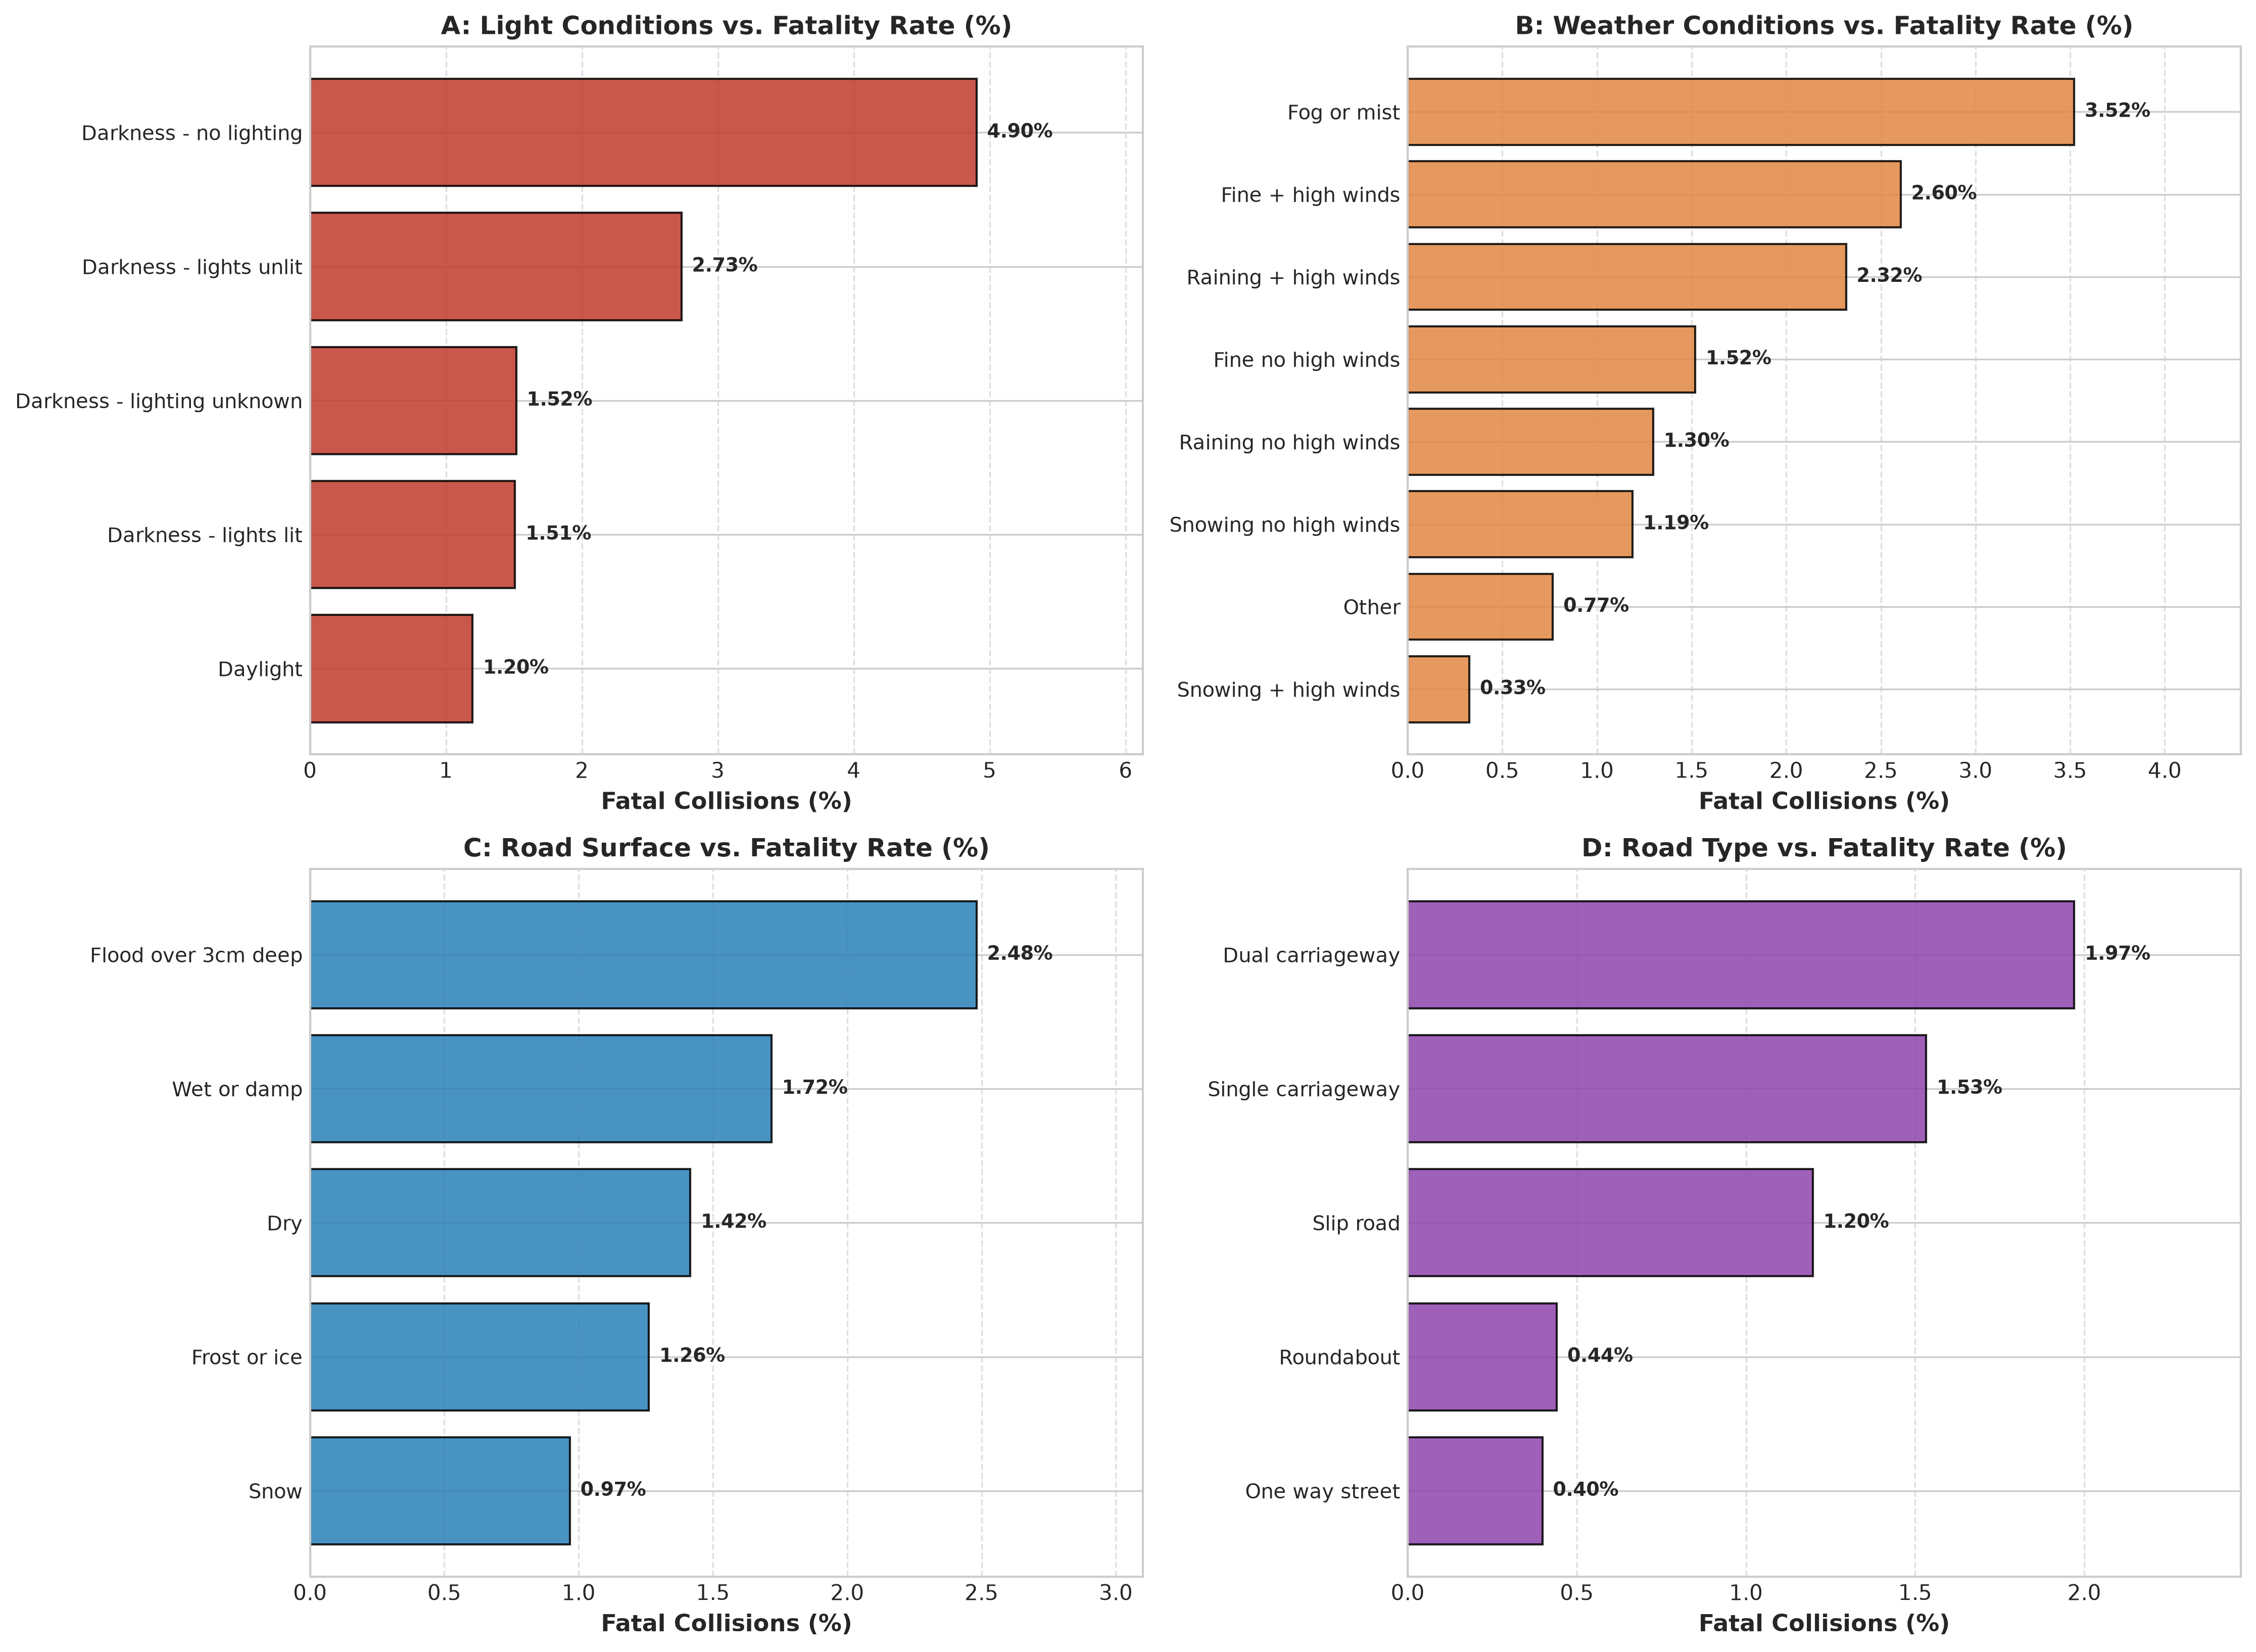

In [7]:
# 7. Plot: Bivariate Risk Profiling (Exposure vs. KSI Rate across Environmental Factors)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Light Conditions
tab_light, _ = compute_bivariate_table(df, 'light_conditions_label')
tab_light = tab_light.sort_values('Fatal %', ascending=True)

ax1 = axes[0, 0]
y_pos = np.arange(len(tab_light))
bars = ax1.barh(y_pos, tab_light['Fatal %'], color='#c0392b', alpha=0.85, edgecolor='black')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(tab_light.index, fontsize=9.5)
ax1.set_title("A: Light Conditions vs. Fatality Rate (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Fatal Collisions (%)", fontweight='semibold')
ax1.grid(axis='x', linestyle='--', alpha=0.6)
for bar in bars:
    w = bar.get_width()
    ax1.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points", va='center', fontweight='bold', fontsize=9)
ax1.set_xlim(0, max(tab_light['Fatal %']) * 1.25)

# 2. Weather Conditions
tab_weather, _ = compute_bivariate_table(df, 'weather_conditions_label')
tab_weather = tab_weather[~tab_weather.index.str.contains('Missing|Unknown')].sort_values('Fatal %', ascending=True)

ax2 = axes[0, 1]
y_pos = np.arange(len(tab_weather))
bars = ax2.barh(y_pos, tab_weather['Fatal %'], color='#e28743', alpha=0.85, edgecolor='black')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(tab_weather.index, fontsize=9.5)
ax2.set_title("B: Weather Conditions vs. Fatality Rate (%)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Fatal Collisions (%)", fontweight='semibold')
ax2.grid(axis='x', linestyle='--', alpha=0.6)
for bar in bars:
    w = bar.get_width()
    ax2.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points", va='center', fontweight='bold', fontsize=9)
ax2.set_xlim(0, max(tab_weather['Fatal %']) * 1.25)

# 3. Road Surface Conditions
tab_surface, _ = compute_bivariate_table(df, 'road_surface_conditions_label')
tab_surface = tab_surface[~tab_surface.index.str.contains('Missing|Unknown')].sort_values('Fatal %', ascending=True)

ax3 = axes[1, 0]
y_pos = np.arange(len(tab_surface))
bars = ax3.barh(y_pos, tab_surface['Fatal %'], color='#2980b9', alpha=0.85, edgecolor='black')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(tab_surface.index, fontsize=9.5)
ax3.set_title("C: Road Surface vs. Fatality Rate (%)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Fatal Collisions (%)", fontweight='semibold')
ax3.grid(axis='x', linestyle='--', alpha=0.6)
for bar in bars:
    w = bar.get_width()
    ax3.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points", va='center', fontweight='bold', fontsize=9)
ax3.set_xlim(0, max(tab_surface['Fatal %']) * 1.25)

# 4. Road Type
tab_road, _ = compute_bivariate_table(df, 'road_type_label')
tab_road = tab_road[~tab_road.index.str.contains('Missing|Unknown')].sort_values('Fatal %', ascending=True)

ax4 = axes[1, 1]
y_pos = np.arange(len(tab_road))
bars = ax4.barh(y_pos, tab_road['Fatal %'], color='#8e44ad', alpha=0.85, edgecolor='black')
ax4.set_yticks(y_pos)
ax4.set_yticklabels(tab_road.index, fontsize=9.5)
ax4.set_title("D: Road Type vs. Fatality Rate (%)", fontsize=12, fontweight='bold')
ax4.set_xlabel("Fatal Collisions (%)", fontweight='semibold')
ax4.grid(axis='x', linestyle='--', alpha=0.6)
for bar in bars:
    w = bar.get_width()
    ax4.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points", va='center', fontweight='bold', fontsize=9)
ax4.set_xlim(0, max(tab_road['Fatal %']) * 1.25)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig3_environmental_bivariate_risk.png"
plt.savefig(fig_path)
plt.show()



In [8]:
# 8. Speed Limit & Urban/Rural Cross-Tabulations and Interaction Matrix
speed_ct = pd.crosstab(df['speed_limit'], df['collision_severity_label'])[SEVERITY_ORDER]
speed_pct = pd.crosstab(df['speed_limit'], df['collision_severity_label'], normalize='index')[SEVERITY_ORDER] * 100

speed_summary = pd.DataFrame({
    'Total Collisions': speed_ct.sum(axis=1),
    'Fatal %': speed_pct['Fatal'],
    'Serious %': speed_pct['Serious'],
    'Slight %': speed_pct['Slight'],
    'KSI %': speed_pct['Fatal'] + speed_pct['Serious']
})

display(speed_summary.style.format({
    'Total Collisions': '{:,}', 'Fatal %': '{:.2f}%', 'Serious %': '{:.2f}%', 
    'Slight %': '{:.2f}%', 'KSI %': '{:.2f}%'
}))

# Urban vs Rural breakdown
urban_rural_ct = pd.crosstab(df['urban_or_rural_area_label'], df['collision_severity_label'])[SEVERITY_ORDER]
urban_rural_pct = pd.crosstab(df['urban_or_rural_area_label'], df['collision_severity_label'], normalize='index')[SEVERITY_ORDER] * 100

ur_summary = pd.DataFrame({
    'Total Collisions': urban_rural_ct.sum(axis=1),
    'Fatal %': urban_rural_pct['Fatal'],
    'Serious %': urban_rural_pct['Serious'],
    'Slight %': urban_rural_pct['Slight'],
    'KSI %': urban_rural_pct['Fatal'] + urban_rural_pct['Serious']
})

display(ur_summary.style.format({
    'Total Collisions': '{:,}', 'Fatal %': '{:.2f}%', 'Serious %': '{:.2f}%', 
    'Slight %': '{:.2f}%', 'KSI %': '{:.2f}%'
}))

# Speed Limit & Urban/Rural Interaction
speed_ur = df.groupby(['speed_limit', 'urban_or_rural_area_label'])['collision_severity_label'].apply(
    lambda s: (s == 'Fatal').mean() * 100
).unstack()

display(speed_ur.style.format('{:.2f}%'))

,Total Collisions,Fatal %,Serious %,Slight %,KSI %
speed_limit,,,,,
20.000000,"72,093",0.43%,16.97%,82.61%,17.39%
30.000000,"289,010",0.86%,19.97%,79.17%,20.83%
40.000000,"44,794",1.77%,22.34%,75.89%,24.11%
50.000000,"21,870",2.92%,23.52%,73.56%,26.44%
60.000000,"63,182",3.95%,29.13%,66.92%,33.08%
70.000000,"29,042",3.20%,20.19%,76.61%,23.39%


,Total Collisions,Fatal %,Serious %,Slight %,KSI %
urban_or_rural_area_label,,,,,
Rural,"167,859",2.84%,25.18%,71.98%,28.02%
Urban,"352,132",0.82%,19.05%,80.13%,19.87%


urban_or_rural_area_label,Rural,Urban
speed_limit,,
20.000000,1.17%,0.40%
30.000000,1.18%,0.80%
40.000000,1.95%,1.60%
50.000000,3.35%,1.70%
60.000000,4.03%,1.74%
70.000000,3.26%,2.80%


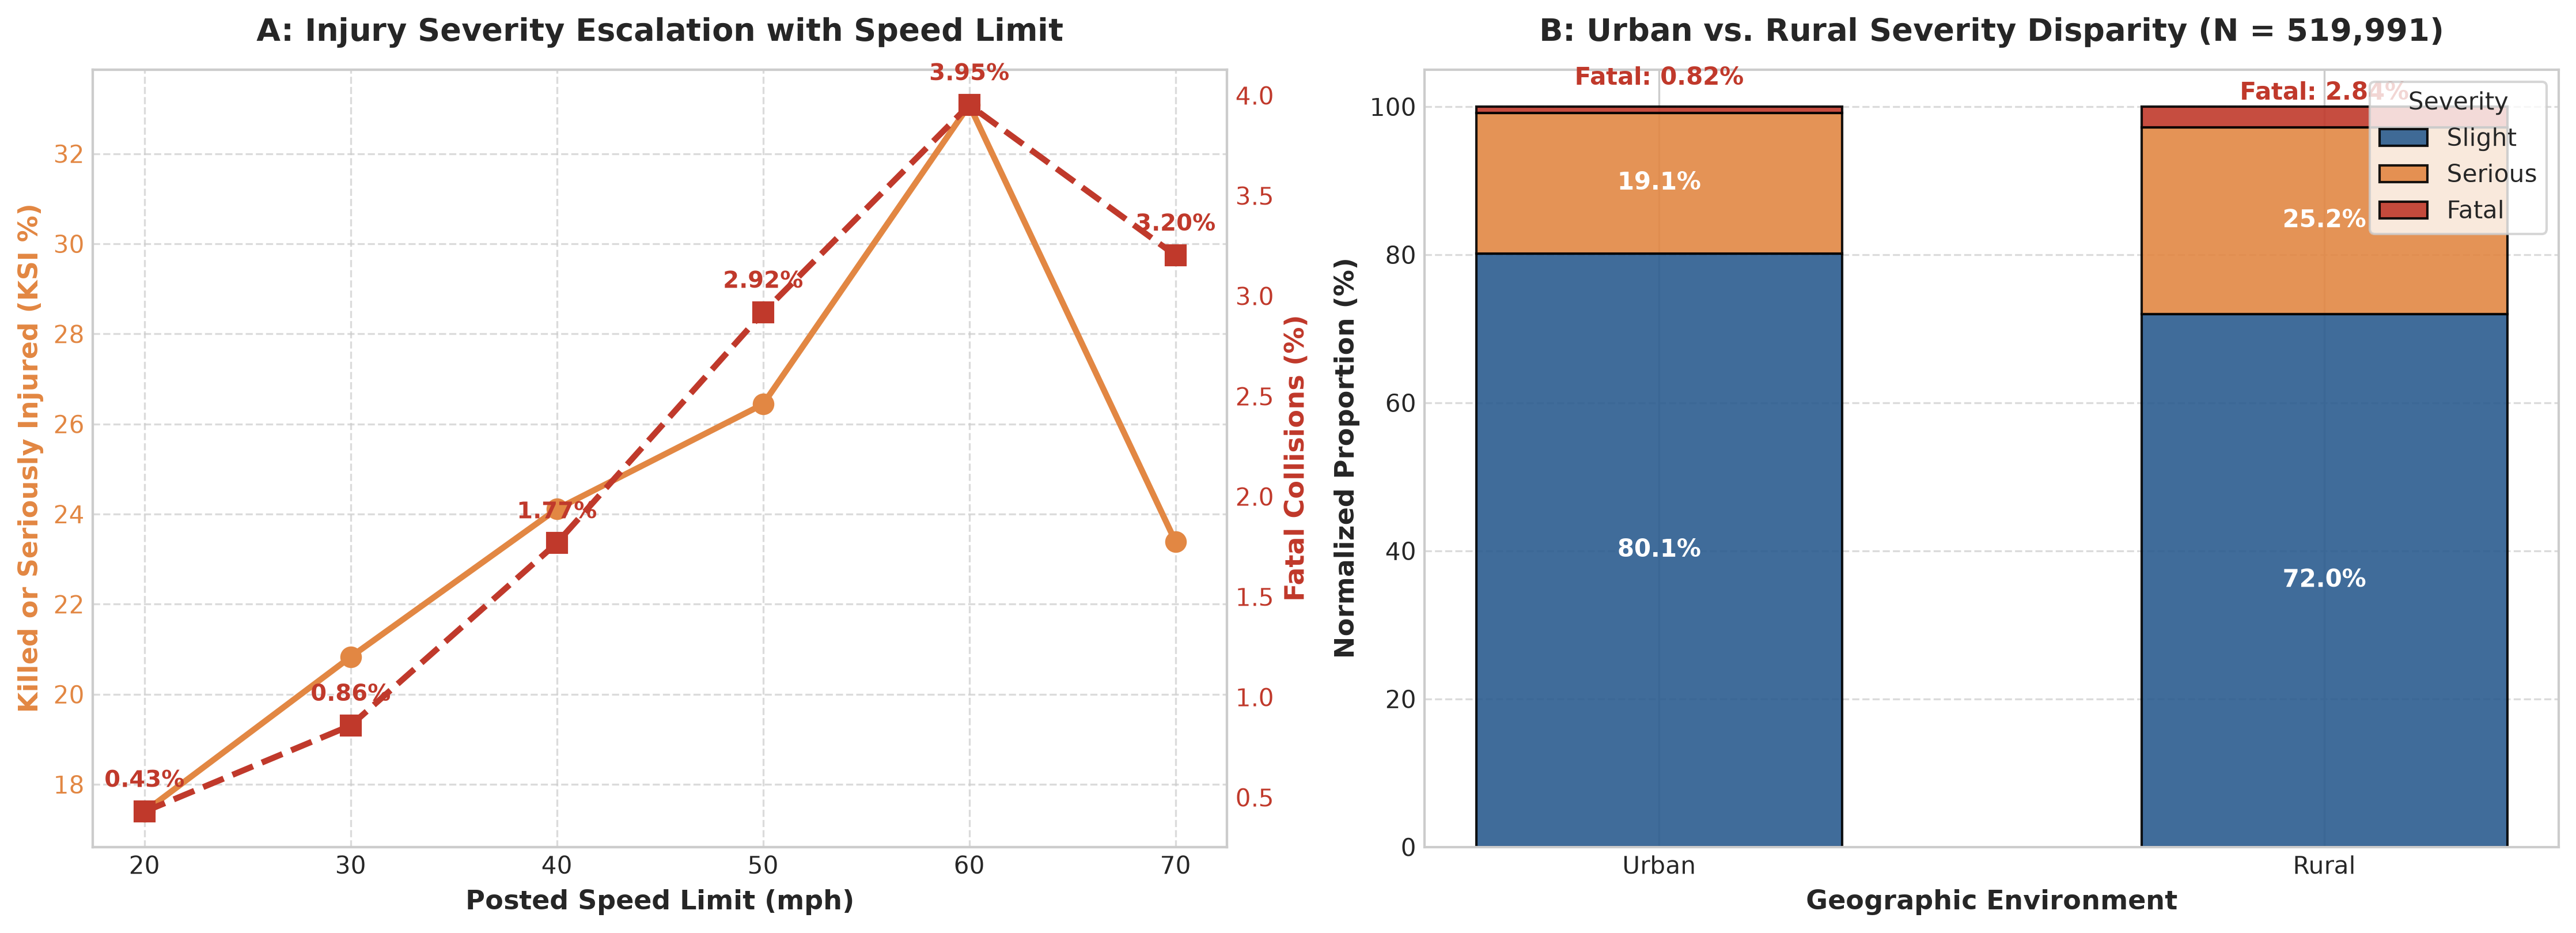

In [9]:
# 9. Plot: Speed Limit Kinetic Curve and Urban vs. Rural Severity Disparity
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Speed Limit Kinetic Curve
valid_speeds = [20, 30, 40, 50, 60, 70]
speed_sub = speed_summary.loc[valid_speeds]

ax1.plot(speed_sub.index, speed_sub['KSI %'], marker='o', color='#e28743', 
         linewidth=2.5, markersize=8, label='KSI % (Fatal + Serious)')
ax1.set_ylabel("Killed or Seriously Injured (KSI %)", color='#e28743', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#e28743')
ax1.set_xlabel("Posted Speed Limit (mph)", fontweight='bold')
ax1.set_title("A: Injury Severity Escalation with Speed Limit", fontsize=13, fontweight='bold', pad=12)
ax1.set_xticks(valid_speeds)
ax1.grid(True, linestyle='--', alpha=0.7)

# Twin axis for Fatal % (due to lower magnitude)
ax1_twin = ax1.twinx()
ax1_twin.plot(speed_sub.index, speed_sub['Fatal %'], marker='s', color='#c0392b', 
              linewidth=2.5, markersize=8, linestyle='--', label='Fatal %')
ax1_twin.set_ylabel("Fatal Collisions (%)", color='#c0392b', fontweight='bold')
ax1_twin.tick_params(axis='y', labelcolor='#c0392b')
ax1_twin.grid(False)

# Annotate points on Fatal curve
for x, y in zip(speed_sub.index, speed_sub['Fatal %']):
    ax1_twin.annotate(f"{y:.2f}%", (x, y), xytext=(0, 8), textcoords="offset points",
                      ha='center', va='bottom', fontweight='bold', color='#c0392b', fontsize=9.5)

# Panel B: Urban vs. Rural Stacked Bar Comparison
ur_plot = ur_summary.loc[['Urban', 'Rural']]
bars_slight = ax2.bar(ur_plot.index, ur_plot['Slight %'], label='Slight', 
                      color=SEVERITY_PALETTE['Slight'], alpha=0.9, edgecolor='black', width=0.55)
bars_serious = ax2.bar(ur_plot.index, ur_plot['Serious %'], bottom=ur_plot['Slight %'], label='Serious', 
                       color=SEVERITY_PALETTE['Serious'], alpha=0.9, edgecolor='black', width=0.55)
bars_fatal = ax2.bar(ur_plot.index, ur_plot['Fatal %'], bottom=ur_plot['Slight %'] + ur_plot['Serious %'], label='Fatal', 
                     color=SEVERITY_PALETTE['Fatal'], alpha=0.9, edgecolor='black', width=0.55)

ax2.set_title("B: Urban vs. Rural Severity Disparity (N = 519,991)", fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel("Normalized Proportion (%)", fontweight='bold')
ax2.set_xlabel("Geographic Environment", fontweight='bold')
ax2.set_ylim(0, 105)
ax2.legend(title="Severity", loc='upper right', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate values
for i, (env, row) in enumerate(ur_plot.iterrows()):
    ax2.text(i, row['Slight %'] / 2, f"{row['Slight %']:.1f}%", ha='center', va='center', color='white', fontweight='bold')
    ax2.text(i, row['Slight %'] + row['Serious %'] / 2, f"{row['Serious %']:.1f}%", ha='center', va='center', color='white', fontweight='bold')
    ax2.text(i, row['Slight %'] + row['Serious %'] + 3, f"Fatal: {row['Fatal %']:.2f}%", ha='center', va='bottom', color='#c0392b', fontweight='bold')

plt.tight_layout()
fig_path = FIGURES_DIR / "fig4_speed_limit_urban_rural.png"
plt.savefig(fig_path)
plt.show()



In [10]:
# 10. Temporal Aggregations: Hourly Diurnal Cycle (Commute Paradox) & Day of Week
hourly_stats = df.groupby('collision_hour').agg(
    total_accidents=('collision_severity_label', 'count'),
    fatal_accidents=('collision_severity_label', lambda s: (s == 'Fatal').sum()),
    fatal_pct=('collision_severity_label', lambda s: (s == 'Fatal').mean() * 100),
    serious_pct=('collision_severity_label', lambda s: (s == 'Serious').mean() * 100),
    ksi_pct=('collision_severity_label', lambda s: (s.isin(['Serious', 'Fatal'])).mean() * 100)
)

display(hourly_stats.style.format({
    'total_accidents': '{:,}', 'fatal_accidents': '{:,}',
    'fatal_pct': '{:.2f}%', 'serious_pct': '{:.2f}%', 'ksi_pct': '{:.2f}%'
}))

# Day of Week Aggregation
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_stats = df.groupby('day_of_week_name').agg(
    total_accidents=('collision_severity_label', 'count'),
    fatal_pct=('collision_severity_label', lambda s: (s == 'Fatal').mean() * 100),
    ksi_pct=('collision_severity_label', lambda s: (s.isin(['Serious', 'Fatal'])).mean() * 100)
).reindex(dow_order)

display(dow_stats.style.format({
    'total_accidents': '{:,}', 'fatal_pct': '{:.2f}%', 'ksi_pct': '{:.2f}%'
}))

,total_accidents,fatal_accidents,fatal_pct,serious_pct,ksi_pct
collision_hour,,,,,
0,"8,019",265,3.30%,25.78%,29.08%
1,"5,756",192,3.34%,25.69%,29.03%
2,"4,167",166,3.98%,26.40%,30.38%
3,"3,524",150,4.26%,25.45%,29.71%
4,"3,213",131,4.08%,25.46%,29.54%
5,"4,929",187,3.79%,25.20%,28.99%
6,"9,965",208,2.09%,22.47%,24.56%
7,"21,390",216,1.01%,20.55%,21.56%
8,"32,927",246,0.75%,17.31%,18.06%


,total_accidents,fatal_pct,ksi_pct
day_of_week_name,,,
Monday,"71,718",1.41%,21.80%
Tuesday,"75,902",1.25%,21.28%
Wednesday,"77,711",1.30%,21.57%
Thursday,"79,202",1.36%,21.89%
Friday,"85,988",1.40%,22.04%
Saturday,"71,032",1.77%,24.33%
Sunday,"58,438",1.94%,25.50%


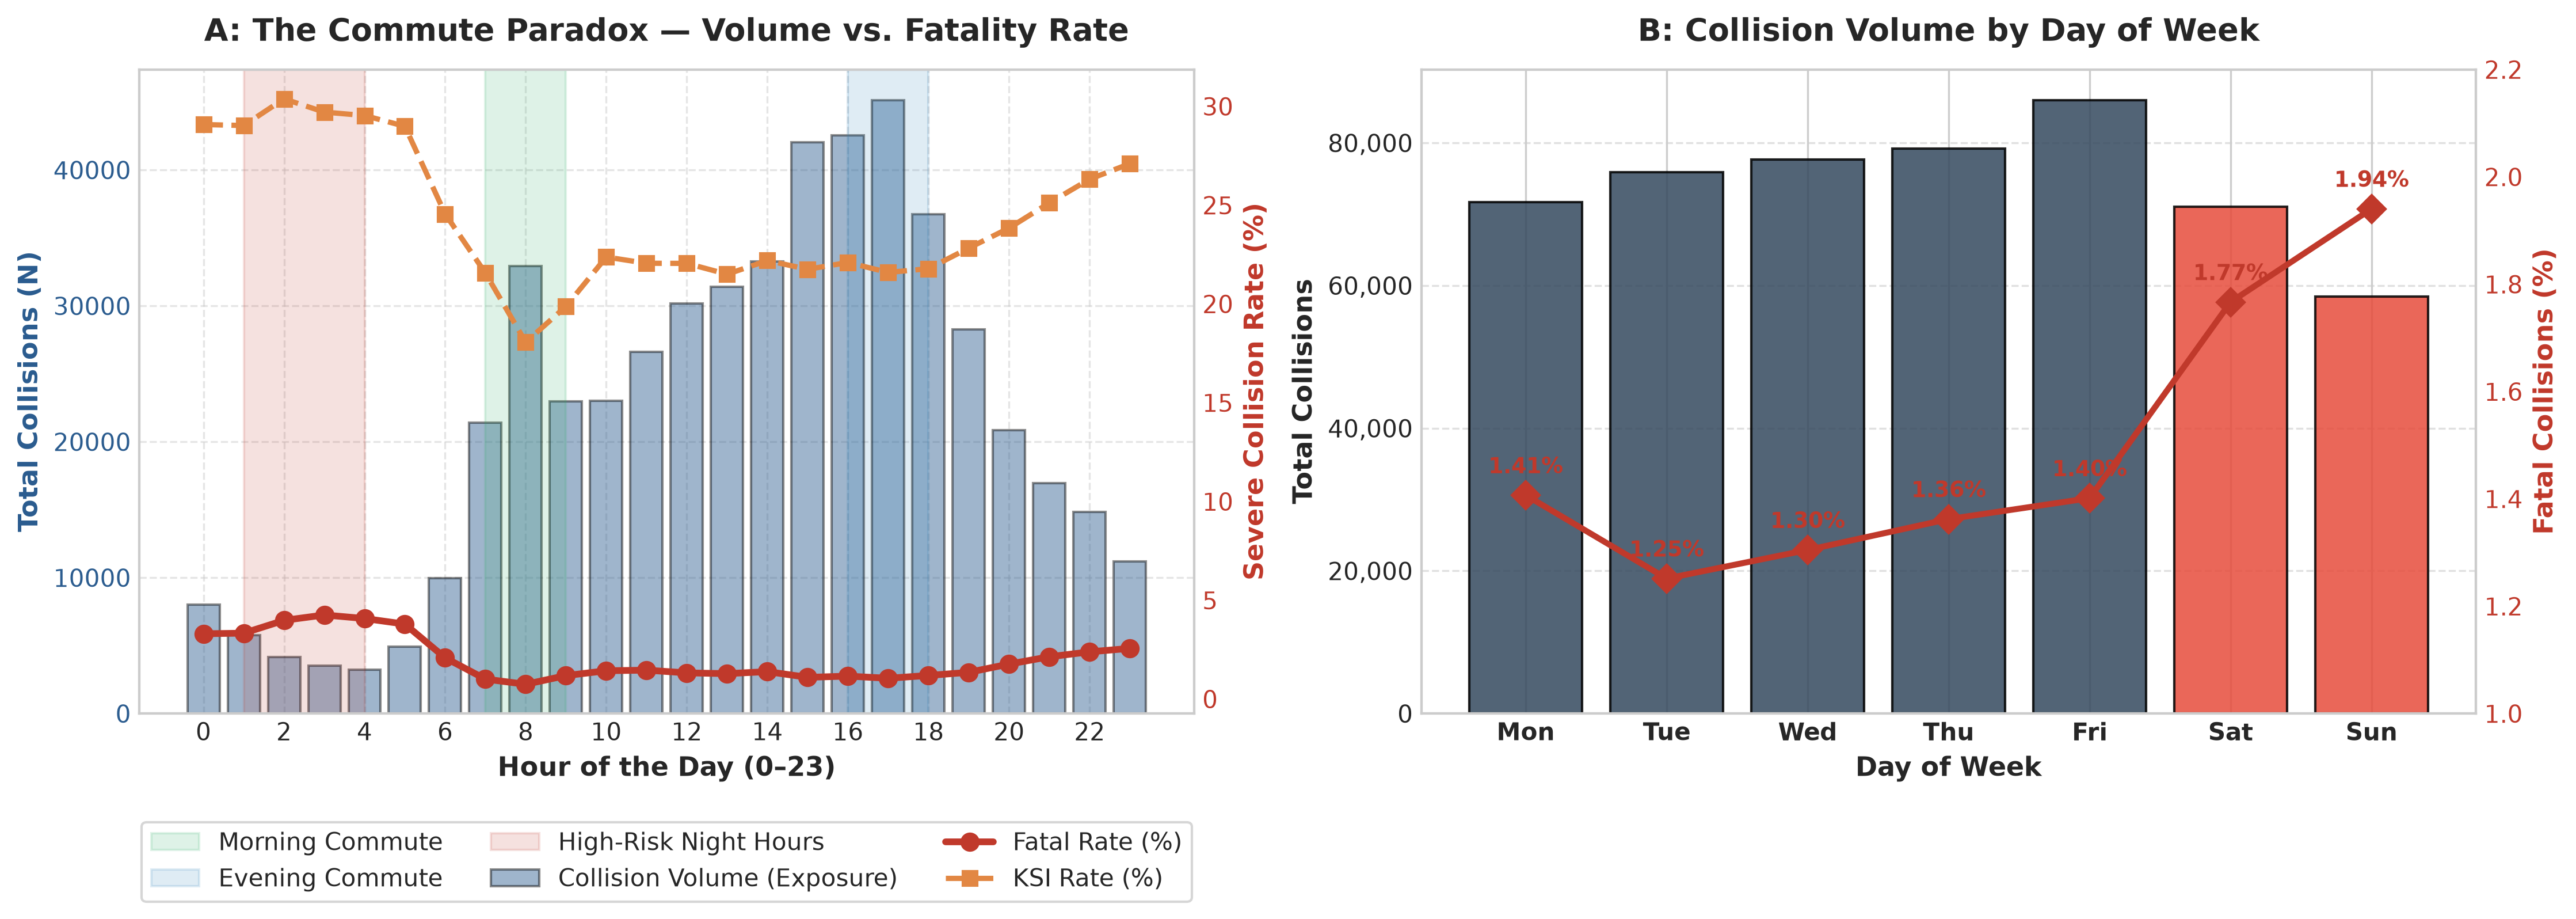

In [11]:
# 11. Plot: Diurnal Volume vs. Severity Rate (Commute Paradox) & Weekly Pattern
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Dual-Axis Commute Paradox
hours = hourly_stats.index
ax1.bar(hours, hourly_stats['total_accidents'], color='#2b5c8f', alpha=0.45, edgecolor='black', label='Collision Volume (Exposure)')
ax1.set_xlabel("Hour of the Day (0–23)", fontweight='bold')
ax1.set_ylabel("Total Collisions (N)", color='#2b5c8f', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2b5c8f')
ax1.set_xticks(range(0, 24, 2))
ax1.set_title("A: The Commute Paradox — Volume vs. Fatality Rate", fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.5)

# Twin axis for Fatal %
ax1_twin = ax1.twinx()
ax1_twin.plot(hours, hourly_stats['fatal_pct'], color='#c0392b', marker='o', linewidth=2.8, markersize=7, label='Fatal Rate (%)')
ax1_twin.plot(hours, hourly_stats['ksi_pct'], color='#e28743', marker='s', linewidth=2.2, markersize=6, linestyle='--', label='KSI Rate (%)')
ax1_twin.set_ylabel("Severe Collision Rate (%)", color='#c0392b', fontweight='bold')
ax1_twin.tick_params(axis='y', labelcolor='#c0392b')
ax1_twin.grid(False)

# Highlight Commute Window vs. Late Night
ax1.axvspan(7, 9, color='#27ae60', alpha=0.15, label='Morning Commute')
ax1.axvspan(16, 18, color='#2980b9', alpha=0.15, label='Evening Commute')
ax1.axvspan(1, 4, color='#c0392b', alpha=0.15, label='High-Risk Night Hours')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True)

# Panel B: Day of Week & Weekend Lethality
dow_x = range(len(dow_stats))
bars = ax2.bar(dow_x, dow_stats['total_accidents'], color=['#34495e']*5 + ['#e74c3c', '#e74c3c'], alpha=0.85, edgecolor='black')
ax2.set_xticks(dow_x)
ax2.set_xticklabels([d[:3] for d in dow_stats.index], fontweight='bold')
ax2.set_title("B: Collision Volume by Day of Week", fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel("Total Collisions", fontweight='bold')
ax2.set_xlabel("Day of Week", fontweight='bold')
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x):,}'))
ax2.grid(axis='y', linestyle='--', alpha=0.6)

# Overlay Fatal % line on Day of Week
ax2_twin = ax2.twinx()
ax2_twin.plot(dow_x, dow_stats['fatal_pct'], color='#c0392b', marker='D', linewidth=2.5, markersize=8, label='Fatal %')
ax2_twin.set_ylabel("Fatal Collisions (%)", color='#c0392b', fontweight='bold')
ax2_twin.tick_params(axis='y', labelcolor='#c0392b')
ax2_twin.set_ylim(1.0, 2.2)
ax2_twin.grid(False)

for x, y in zip(dow_x, dow_stats['fatal_pct']):
    ax2_twin.annotate(f"{y:.2f}%", (x, y), xytext=(0, 7), textcoords="offset points",
                      ha='center', va='bottom', fontweight='bold', color='#c0392b', fontsize=9)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig5_diurnal_commute_paradox.png"
plt.savefig(fig_path)
plt.show()



In [12]:
# 12. Numerical Variables Parametric & Non-Parametric Summary & Outlier Analysis
num_cols = ['number_of_vehicles', 'number_of_casualties', 'speed_limit', 'collision_hour']

num_stats = df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
num_stats['IQR'] = num_stats['75%'] - num_stats['25%']
num_stats['Upper Fence (1.5 IQR)'] = num_stats['75%'] + 1.5 * num_stats['IQR']
num_stats['Skewness'] = df[num_cols].skew()
num_stats['Kurtosis'] = df[num_cols].kurtosis()

display(num_stats.style.format({
    'count': '{:,.0f}', 'mean': '{:.2f}', 'std': '{:.2f}', 'min': '{:.0f}',
    '1%': '{:.0f}', '5%': '{:.0f}', '25%': '{:.0f}', '50%': '{:.0f}',
    '75%': '{:.0f}', '95%': '{:.0f}', '99%': '{:.0f}', 'max': '{:.0f}',
    'IQR': '{:.1f}', 'Upper Fence (1.5 IQR)': '{:.1f}', 'Skewness': '{:.2f}', 'Kurtosis': '{:.2f}'
}))

# Inspect extreme multi-vehicle crashes
extreme_veh = df[df['number_of_vehicles'] >= 5]
extreme_cas = df[df['number_of_casualties'] >= 5]
print(f'Multi-vehicle pileups (>= 5 vehicles): {len(extreme_veh):,} ({len(extreme_veh)/len(df)*100:.2f}%), Fatal rate: {(extreme_veh["collision_severity_label"] == "Fatal").mean()*100:.2f}%, Motorway %: {(extreme_veh["first_road_class_label"] == "Motorway").mean()*100:.2f}%')
print(f'Mass-casualty incidents (>= 5 casualties): {len(extreme_cas):,} ({len(extreme_cas)/len(df)*100:.2f}%), Fatal rate: {(extreme_cas["collision_severity_label"] == "Fatal").mean()*100:.2f}%')


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,IQR,Upper Fence (1.5 IQR),Skewness,Kurtosis
number_of_vehicles,"519,991",1.83,0.69,1,1,1,1,2,2,3,4,17,1.0,3.5,1.68,11.99
number_of_casualties,"519,991",1.28,0.71,1,1,1,1,1,1,3,4,70,0.0,1.0,6.63,265.24
speed_limit,"519,991",36.20,14.13,20,20,20,30,30,40,70,70,70,10.0,55.0,1.13,0.11
collision_hour,"519,991",13.72,5.15,0,0,5,10,14,17,22,23,23,7.0,27.5,-0.47,-0.21


Multi-vehicle pileups (>= 5 vehicles): 3,035 (0.58%), Fatal rate: 3.62%, Motorway %: 17.50%
Mass-casualty incidents (>= 5 casualties): 3,711 (0.71%), Fatal rate: 7.79%


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


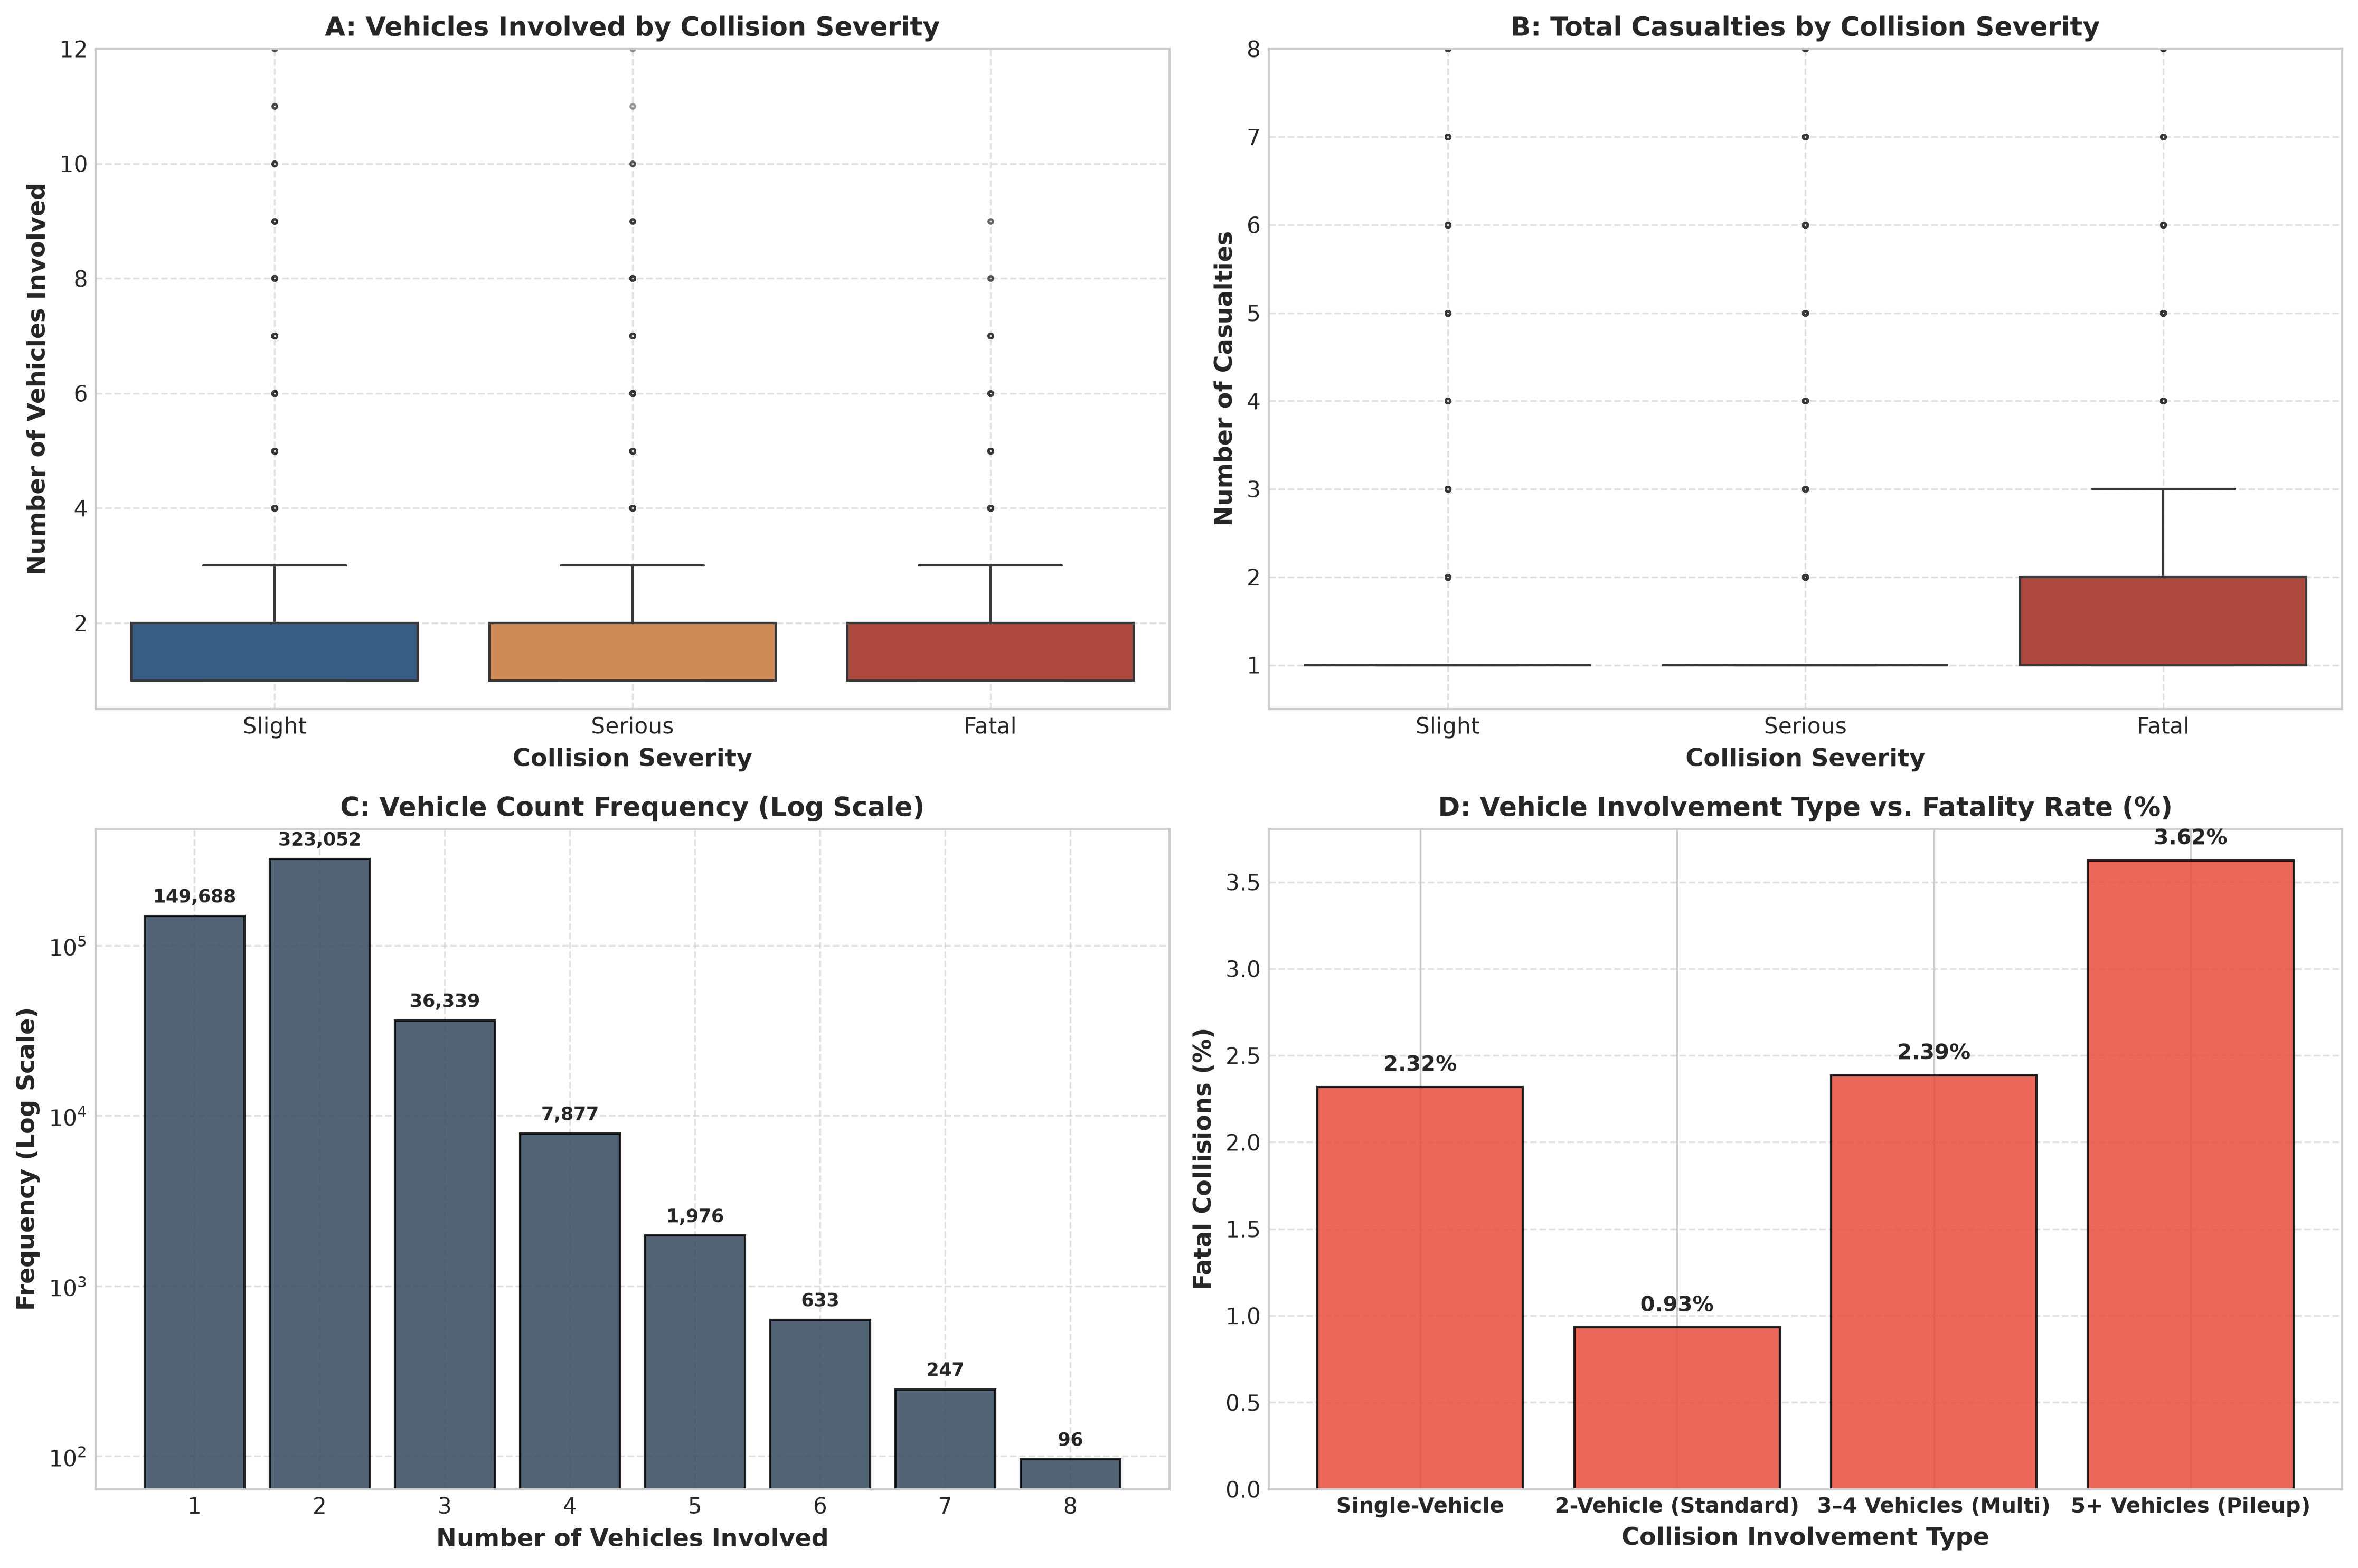

In [13]:
# 13. Plot: Number of Vehicles & Casualties by Severity & Pileup Fatality Rate
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel A: Number of Vehicles by Severity (Boxplot with log scale)
ax1 = axes[0, 0]
sns.boxplot(data=df, x='collision_severity_label', y='number_of_vehicles', order=SEVERITY_ORDER, 
            palette=SEVERITY_PALETTE, ax=ax1, flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
ax1.set_title("A: Vehicles Involved by Collision Severity", fontsize=12, fontweight='bold')
ax1.set_xlabel("Collision Severity", fontweight='semibold')
ax1.set_ylabel("Number of Vehicles Involved", fontweight='semibold')
ax1.set_ylim(0.5, 12)
ax1.grid(True, linestyle='--', alpha=0.6)

# Panel B: Number of Casualties by Severity (Violin plot)
ax2 = axes[0, 1]
sns.boxplot(data=df, x='collision_severity_label', y='number_of_casualties', order=SEVERITY_ORDER, 
            palette=SEVERITY_PALETTE, ax=ax2, flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
ax2.set_title("B: Total Casualties by Collision Severity", fontsize=12, fontweight='bold')
ax2.set_xlabel("Collision Severity", fontweight='semibold')
ax2.set_ylabel("Number of Casualties", fontweight='semibold')
ax2.set_ylim(0.5, 8)
ax2.grid(True, linestyle='--', alpha=0.6)

# Panel C: Vehicle Count Distribution (Log-scaled frequency)
ax3 = axes[1, 0]
veh_counts = df['number_of_vehicles'].value_counts().sort_index().head(8)
bars = ax3.bar(veh_counts.index, veh_counts.values, color='#34495e', edgecolor='black', alpha=0.85)
ax3.set_yscale('log')
ax3.set_title("C: Vehicle Count Frequency (Log Scale)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Number of Vehicles Involved", fontweight='semibold')
ax3.set_ylabel("Frequency (Log Scale)", fontweight='semibold')
ax3.grid(True, linestyle='--', alpha=0.6)
for bar in bars:
    y = bar.get_height()
    ax3.annotate(f"{y:,}", (bar.get_x() + bar.get_width() / 2, y),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Panel D: Vehicle Involvement Category vs. Fatality Rate
ax4 = axes[1, 1]
df['vehicle_category'] = pd.cut(df['number_of_vehicles'], bins=[0, 1, 2, 4, 100], 
                                labels=['Single-Vehicle', '2-Vehicle (Standard)', '3–4 Vehicles (Multi)', '5+ Vehicles (Pileup)'])
veh_cat_stats = df.groupby('vehicle_category')['collision_severity_label'].agg(
    Fatal_Pct=lambda s: (s == 'Fatal').mean() * 100,
    Total='count'
)

bars = ax4.bar(range(len(veh_cat_stats)), veh_cat_stats['Fatal_Pct'], color='#e74c3c', edgecolor='black', alpha=0.85)
ax4.set_xticks(range(len(veh_cat_stats)))
ax4.set_xticklabels(veh_cat_stats.index, fontsize=9.5, fontweight='semibold')
ax4.set_title("D: Vehicle Involvement Type vs. Fatality Rate (%)", fontsize=12, fontweight='bold')
ax4.set_ylabel("Fatal Collisions (%)", fontweight='semibold')
ax4.set_xlabel("Collision Involvement Type", fontweight='semibold')
ax4.grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars:
    y = bar.get_height()
    ax4.annotate(f"{y:.2f}%", (bar.get_x() + bar.get_width() / 2, y),
                 xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontweight='bold', fontsize=9.5)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig6_numerical_distributions_outliers.png"
plt.savefig(fig_path)
plt.show()



In [14]:
# 14. Aligned Ordinal Severity Target & Spearman Rank Correlation Matrix
df['severity_rank'] = 4 - df['collision_severity']

corr_cols = [
    'severity_rank',
    'speed_limit',
    'number_of_vehicles',
    'collision_hour',
    'is_weekend',
    'urban_or_rural_area'
]

corr_labels = [
    'Severity Rank (1=Slt, 3=Ftl)',
    'Posted Speed Limit',
    'Number of Vehicles',
    'Collision Hour',
    'Weekend Indicator',
    'Urban/Rural (1=Urb, 2=Rur)'
]

# Compute Spearman rank correlation matrix
spearman_corr = df[corr_cols].corr(method='spearman')
spearman_corr.columns = corr_labels
spearman_corr.index = corr_labels

display(spearman_corr.style.background_gradient(cmap='coolwarm', vmin=-0.5, vmax=0.5).format('{:.3f}'))

,"Severity Rank (1=Slt, 3=Ftl)",Posted Speed Limit,Number of Vehicles,Collision Hour,Weekend Indicator,"Urban/Rural (1=Urb, 2=Rur)"
"Severity Rank (1=Slt, 3=Ftl)",1.000,0.094,-0.100,0.007,0.033,0.095
Posted Speed Limit,0.094,1.000,0.067,-0.046,0.025,0.639
Number of Vehicles,-0.100,0.067,1.000,0.001,-0.021,0.020
Collision Hour,0.007,-0.046,0.001,1.000,0.005,-0.054
Weekend Indicator,0.033,0.025,-0.021,0.005,1.000,0.029
"Urban/Rural (1=Urb, 2=Rur)",0.095,0.639,0.020,-0.054,0.029,1.000


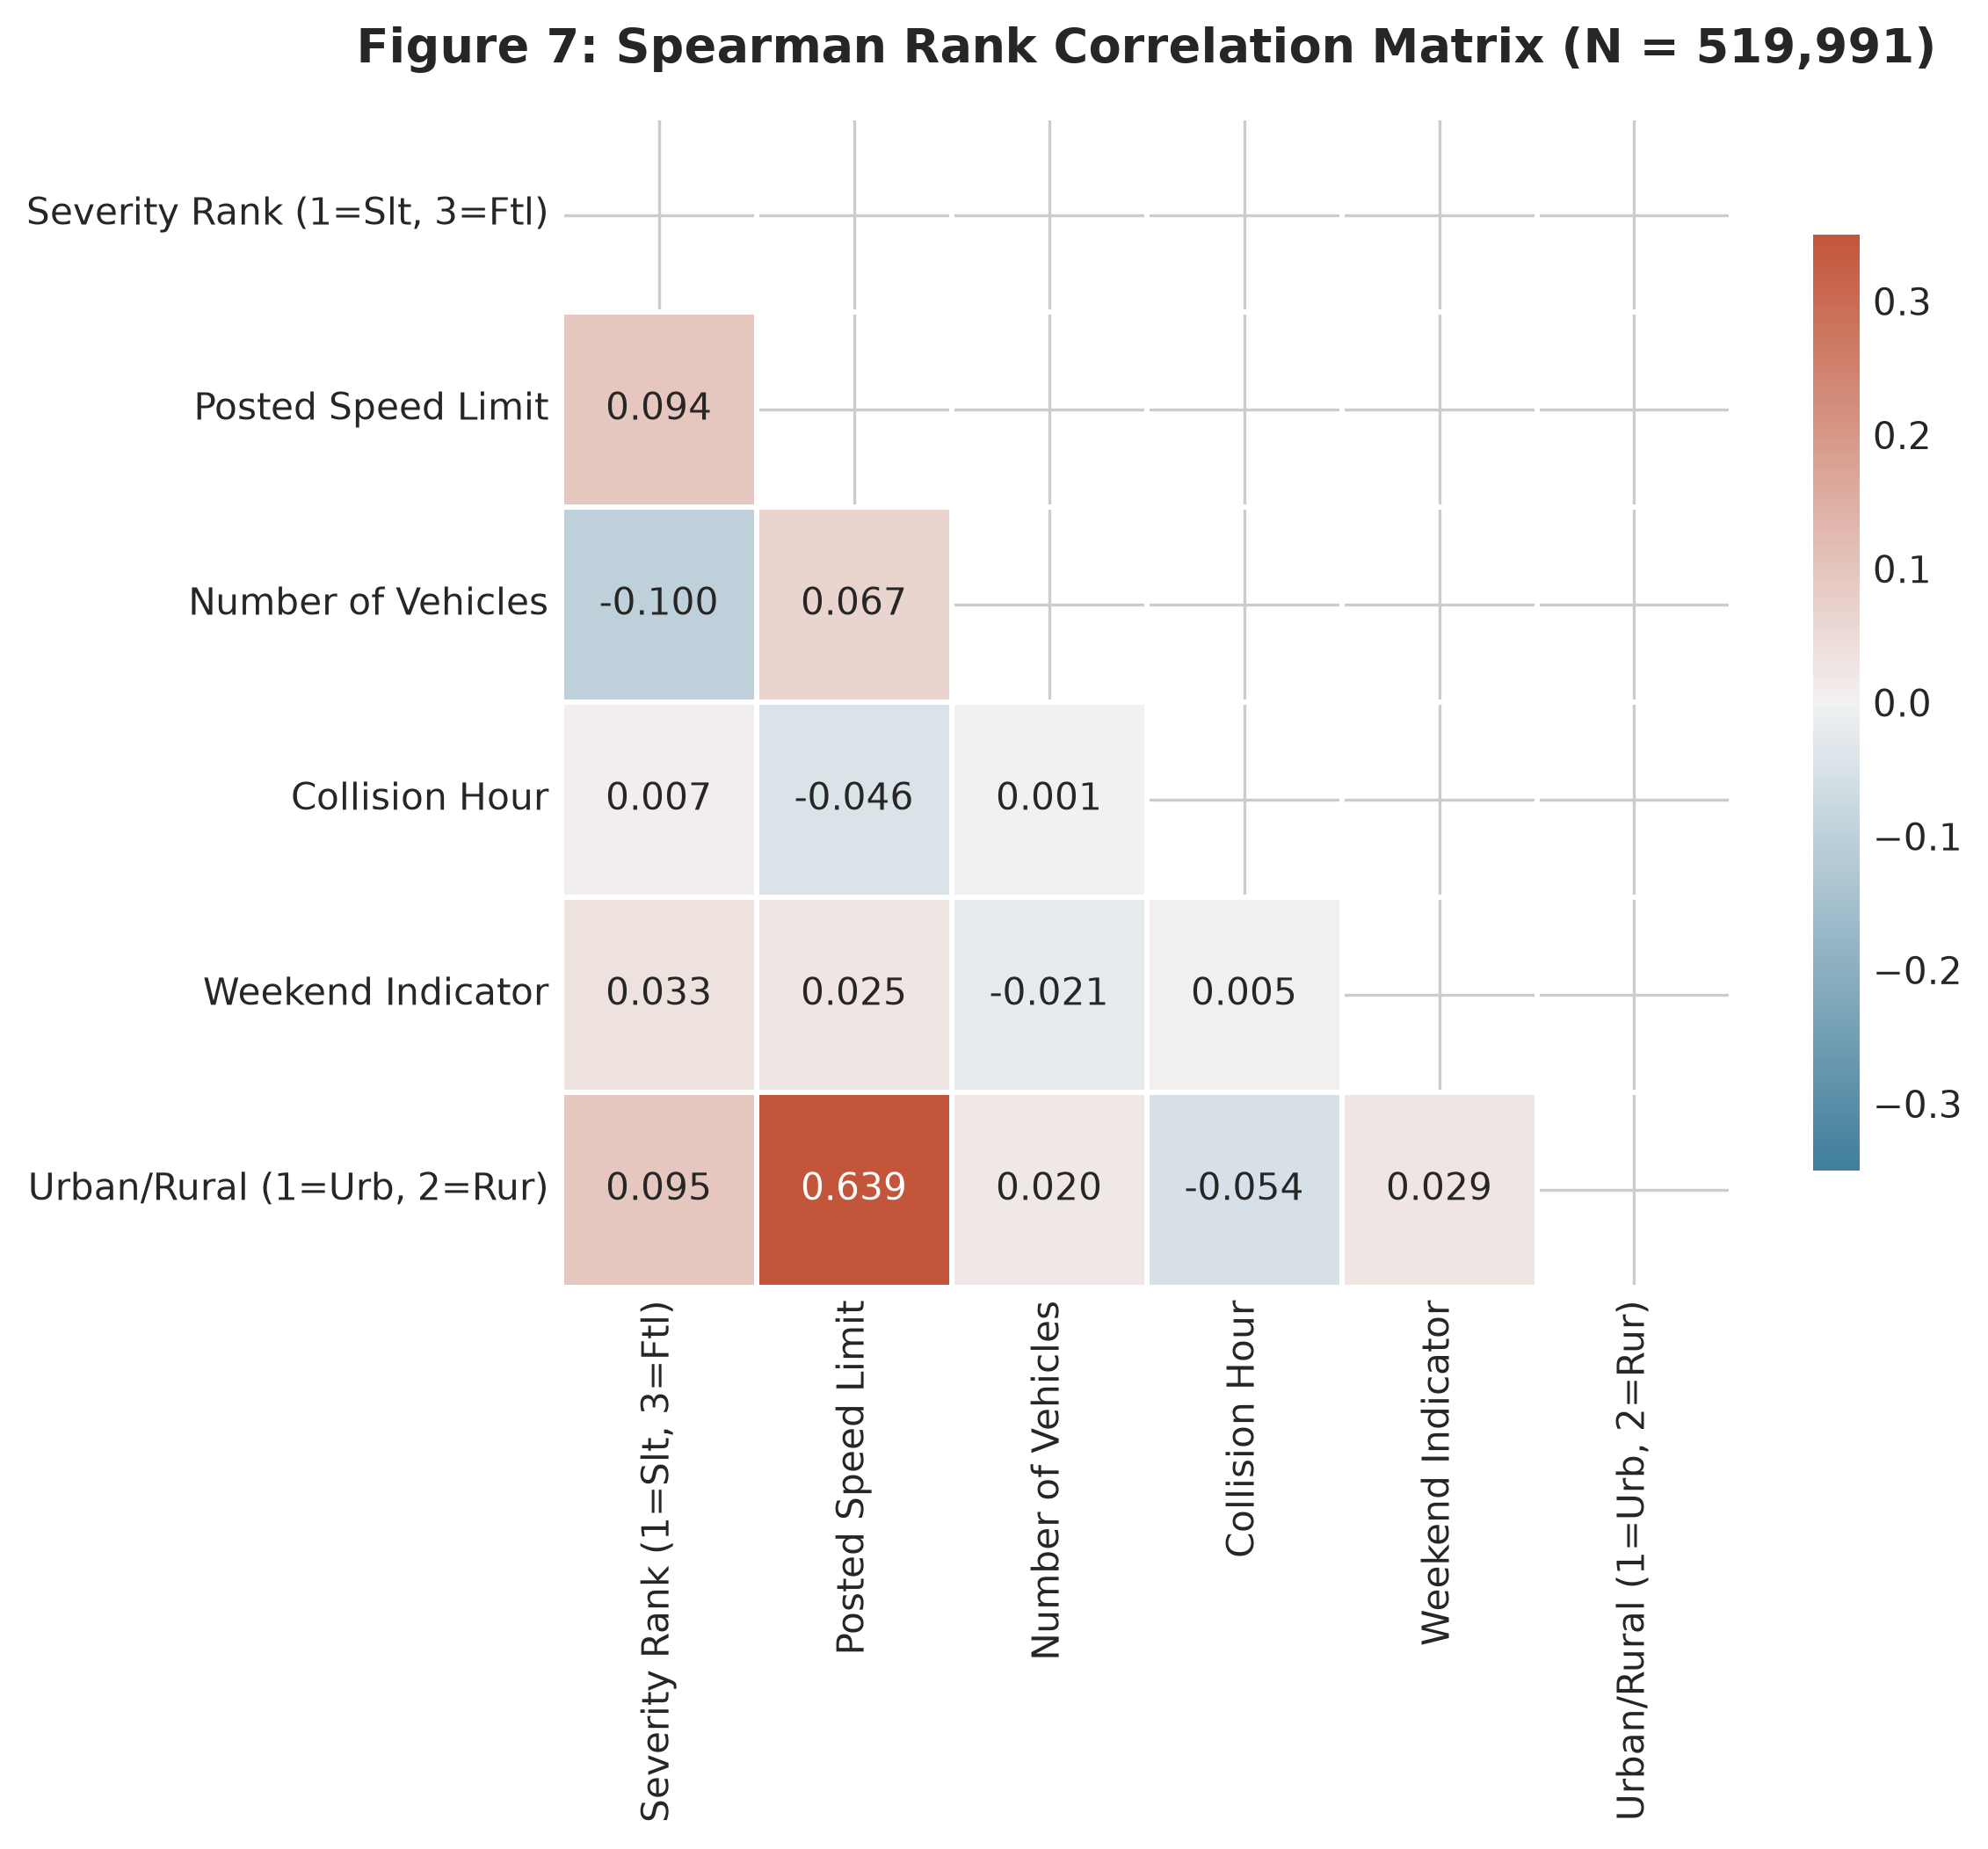

In [15]:
# 15. Plot: Spearman Rank Correlation Heatmap
fig, ax = plt.subplots(figsize=(8.5, 7))

mask = np.triu(np.ones_like(spearman_corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(spearman_corr, mask=mask, cmap=cmap, vmin=-0.35, vmax=0.35, center=0,
            annot=True, fmt='.3f', square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title("Figure 7: Spearman Rank Correlation Matrix (N = 519,991)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
fig_path = FIGURES_DIR / "fig7_correlation_matrix.png"
plt.savefig(fig_path)
plt.show()



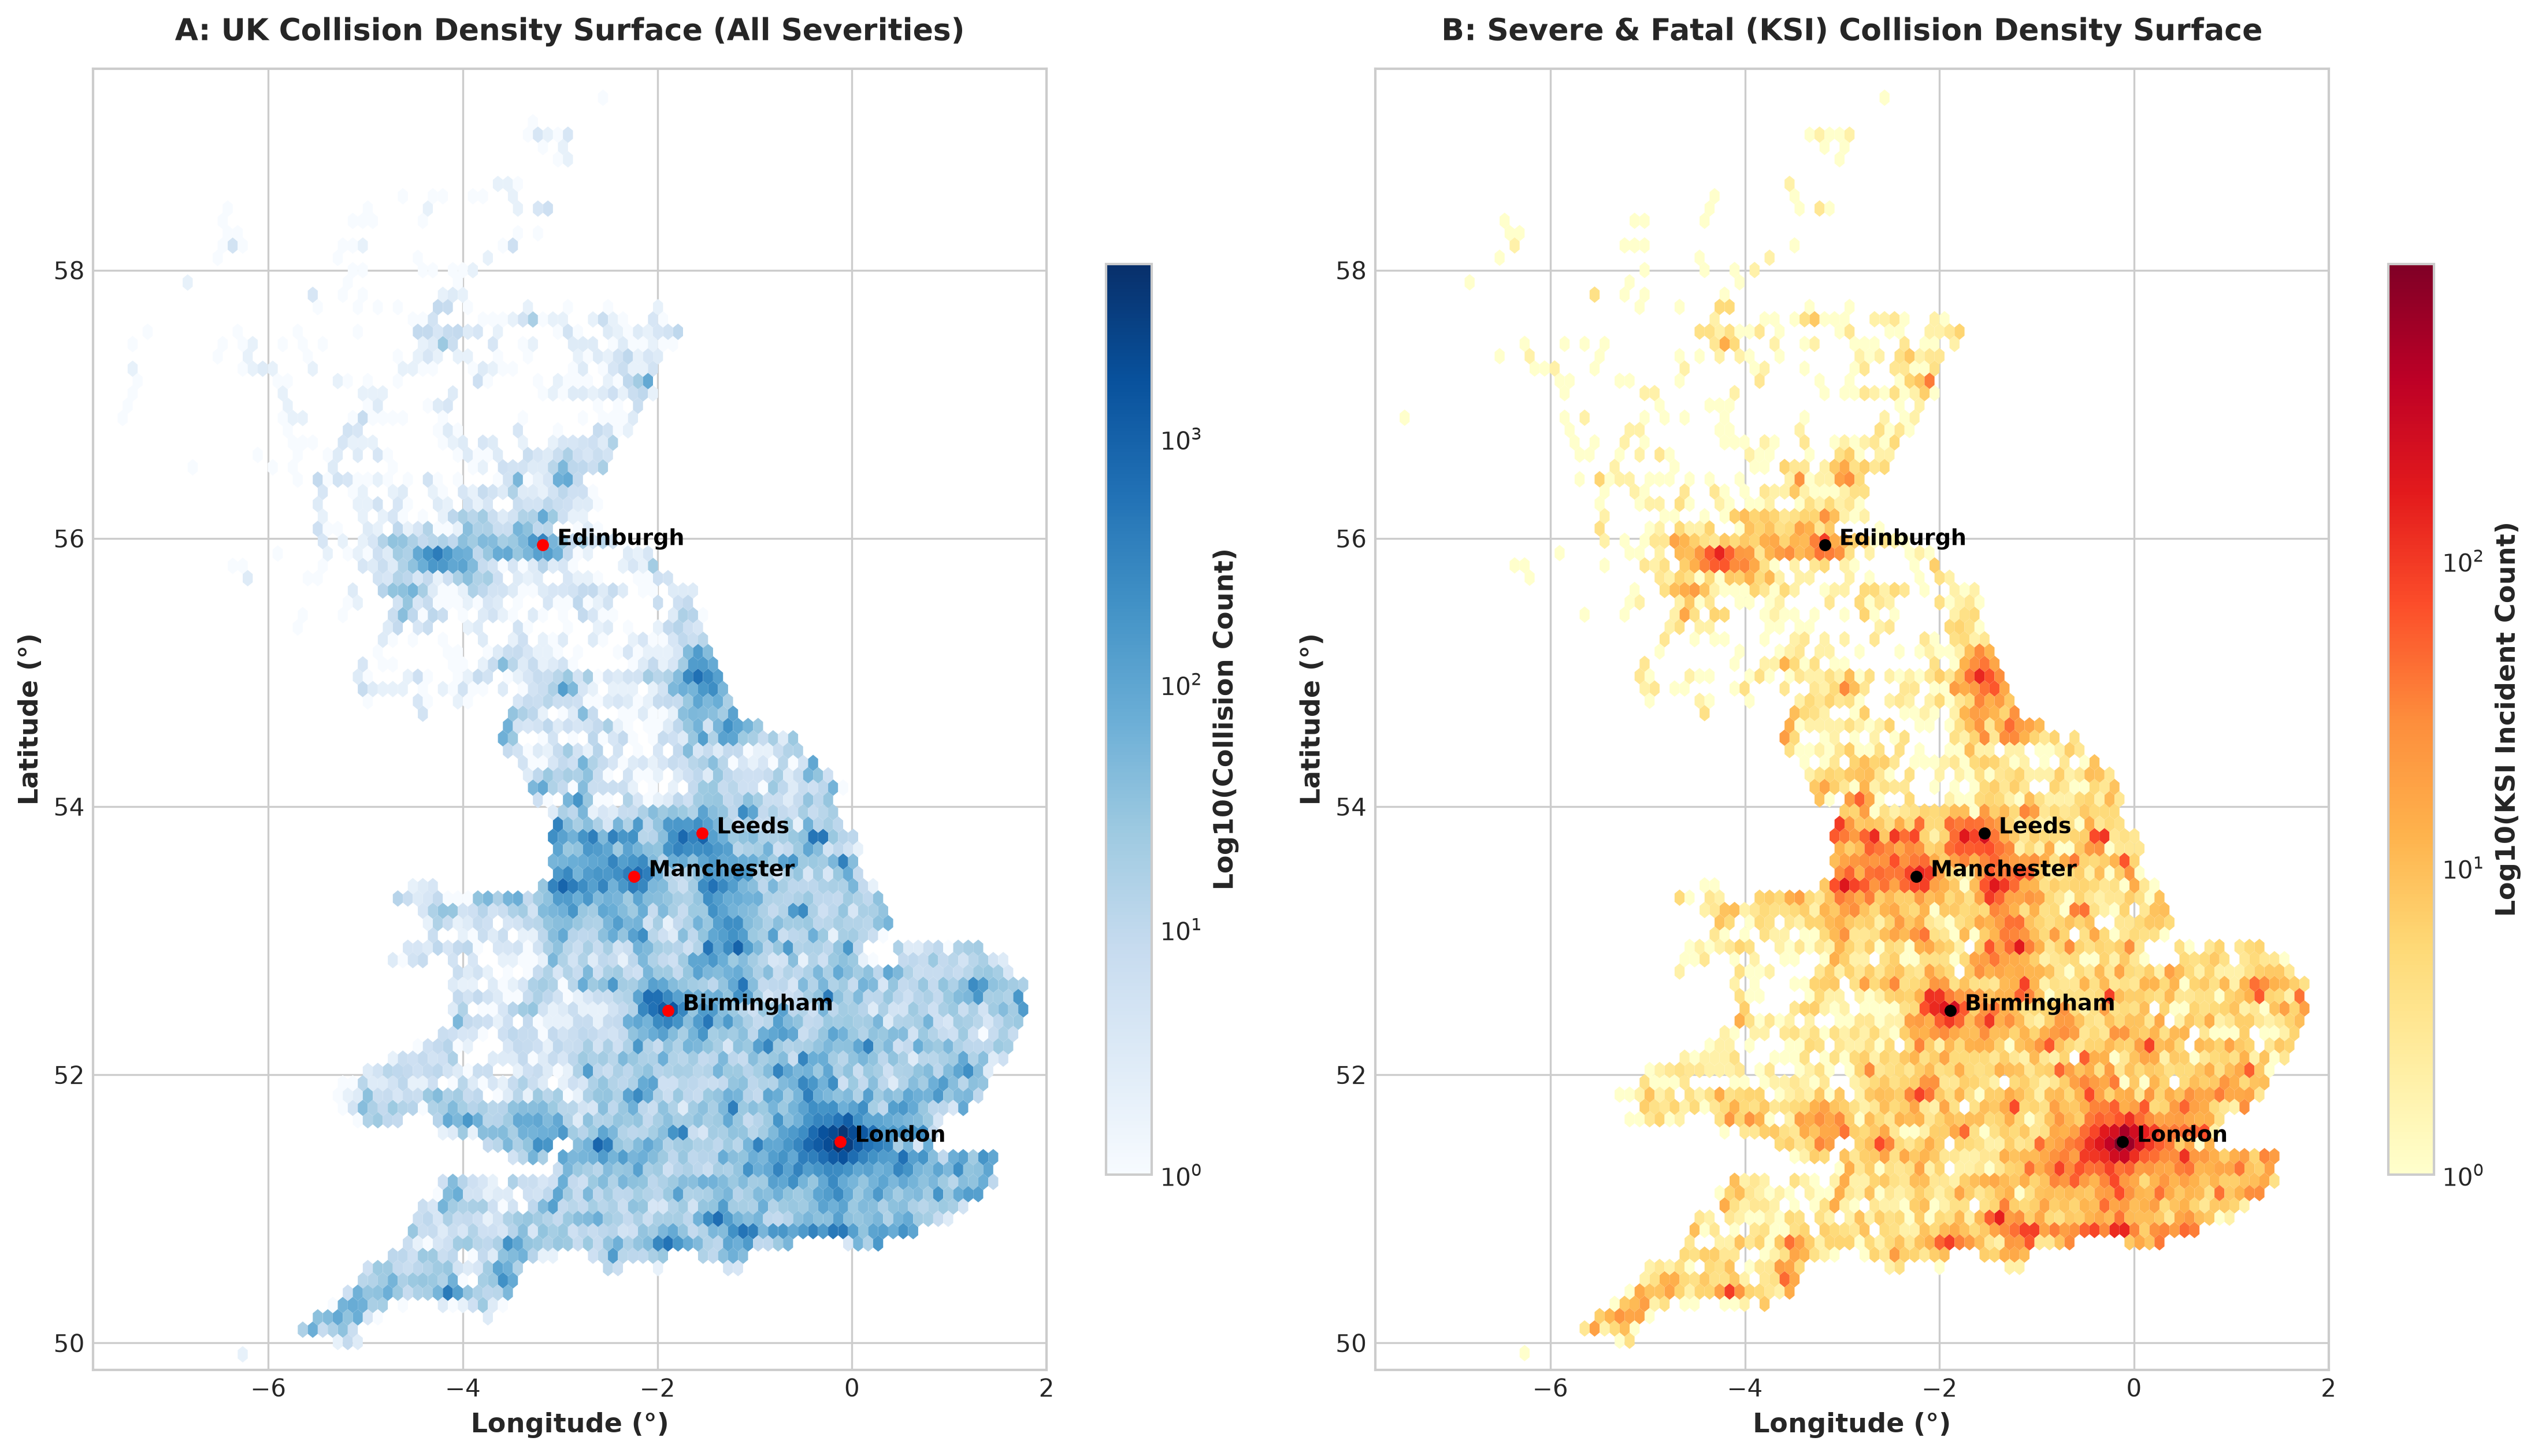

In [16]:
# 16. Plot: UK Spatial Collision Density (Hexbin Surface & Regional Hotspots)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8.5))

# Filter coordinates within valid mainland UK bounding box
geo_df = df[(df['longitude'] >= -7.6) & (df['longitude'] <= 1.8) & 
            (df['latitude'] >= 49.8) & (df['latitude'] <= 59.5)]

# Subsample for responsive hexbin plotting
sample_geo = geo_df.sample(n=min(150000, len(geo_df)), random_state=42)

# Panel A: All Collision Density (Hexbin)
hb1 = ax1.hexbin(sample_geo['longitude'], sample_geo['latitude'], gridsize=90, 
                 cmap='Blues', bins='log', mincnt=1, edgecolors='none')
ax1.set_title("A: UK Collision Density Surface (All Severities)", fontsize=12.5, fontweight='bold', pad=12)
ax1.set_xlabel("Longitude (°)", fontweight='semibold')
ax1.set_ylabel("Latitude (°)", fontweight='semibold')
ax1.set_xlim(-7.8, 2.0)
ax1.set_ylim(49.8, 59.5)
cb1 = plt.colorbar(hb1, ax=ax1, shrink=0.7)
cb1.set_label('Log10(Collision Count)', fontweight='semibold')

# Panel B: Fatal & Serious (KSI) Collisions
sample_ksi = sample_geo[sample_geo['collision_severity_label'].isin(['Serious', 'Fatal'])]
hb2 = ax2.hexbin(sample_ksi['longitude'], sample_ksi['latitude'], gridsize=90, 
                 cmap='YlOrRd', bins='log', mincnt=1, edgecolors='none')
ax2.set_title("B: Severe & Fatal (KSI) Collision Density Surface", fontsize=12.5, fontweight='bold', pad=12)
ax2.set_xlabel("Longitude (°)", fontweight='semibold')
ax2.set_ylabel("Latitude (°)", fontweight='semibold')
ax2.set_xlim(-7.8, 2.0)
ax2.set_ylim(49.8, 59.5)
cb2 = plt.colorbar(hb2, ax=ax2, shrink=0.7)
cb2.set_label('Log10(KSI Incident Count)', fontweight='semibold')

# Annotate Major Metropolises
major_cities = {
    'London': (-0.12, 51.50),
    'Birmingham': (-1.89, 52.48),
    'Manchester': (-2.24, 53.48),
    'Leeds': (-1.54, 53.80),
    'Edinburgh': (-3.18, 55.95)
}

for city, (lon, lat) in major_cities.items():
    ax1.plot(lon, lat, 'ro', markersize=4)
    ax1.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', color='black')
    ax2.plot(lon, lat, 'ko', markersize=4)
    ax2.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
fig_path = FIGURES_DIR / "fig8_spatial_collision_density.png"
plt.savefig(fig_path)
plt.show()

